In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import graphviz
import  sklearn
import xgboost as xgb
warnings.filterwarnings('ignore')
\
from sklearn.model_selection import train_test_split,cross_val_score,GridSearchCV
from sklearn.datasets import make_classification,make_moons
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,r2_score,mean_squared_error,RocCurveDisplay,f1_score,precision_score,roc_auc_score,recall_score,average_precision_score,mean_absolute_error
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.linear_model import LogisticRegression,LinearRegression,Ridge,Lasso
from sklearn.tree import DecisionTreeClassifier,plot_tree,export_text
from sklearn.ensemble import RandomForestClassifier,RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier,NearestNeighbors
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.inspection import DecisionBoundaryDisplay
from math import inf
from scipy import stats
import seaborn as sns

warnings.filterwarnings('ignore')
%matplotlib inline
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

In [2]:
df =pd.read_csv('predictive_maintenance_v3.csv')
df.head()

,timestamp,machine_id,machine_type,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,operating_mode,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,failure_type,estimated_repair_cost
0,2024-01-01 00:00:00,1,CNC,0.81,49.51,5.10,23.6,860.9,idle,273.80,13.9,61.00,0,none,0
1,2024-01-01 00:03:00,1,CNC,0.75,40.58,5.30,23.6,899.6,idle,273.85,10.2,60.95,0,none,0
2,2024-01-01 00:21:00,1,CNC,0.71,49.70,NaN,21.3,862.7,idle,274.15,13.6,60.65,0,none,0
3,2024-01-01 00:45:00,1,CNC,0.76,43.04,4.79,22.6,870.4,idle,274.55,13.4,60.25,0,none,0
4,2024-01-01 00:54:00,1,CNC,0.88,41.39,4.44,22.2,881.9,idle,274.70,10.8,60.10,0,none,0


In [5]:
from datetime import datetime

now=datetime.now()

timestamp_float=now.timestamp()
print(timestamp_float)

1792741530.650994


In [6]:
pd.set_option("display.max_columns", None)

In [7]:
sns.set_style("whitegrid")

In [8]:
df.tail()

,timestamp,machine_id,machine_type,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,operating_mode,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,failure_type,estimated_repair_cost
24037,2024-01-14 22:17:56,20,Robotic Arm,0.98,37.18,5.27,45.0,361.8,normal,163.43,10.2,0.5,0,none,0
24038,2024-01-14 22:41:56,20,Robotic Arm,0.45,33.90,2.21,18.9,159.5,idle,163.83,11.0,0.5,0,none,0
24039,2024-01-14 22:58:56,20,Robotic Arm,0.40,29.15,2.29,19.0,159.5,idle,164.12,16.2,0.5,0,none,0
24040,2024-01-14 23:23:56,20,Robotic Arm,0.45,31.47,2.45,18.0,151.4,idle,164.53,16.7,0.5,0,none,0
24041,2024-01-14 23:52:56,20,Robotic Arm,0.44,33.73,2.25,14.8,153.4,idle,165.02,9.2,0.5,0,none,0


In [9]:
df.shape

(24042, 15)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24042 entries, 0 to 24041
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   timestamp                24042 non-null  str    
 1   machine_id               24042 non-null  int64  
 2   machine_type             24042 non-null  str    
 3   vibration_rms            23042 non-null  float64
 4   temperature_motor        23208 non-null  float64
 5   current_phase_avg        23311 non-null  float64
 6   pressure_level           23118 non-null  float64
 7   rpm                      23509 non-null  float64
 8   operating_mode           24042 non-null  str    
 9   hours_since_maintenance  24042 non-null  float64
 10  ambient_temp             24042 non-null  float64
 11  rul_hours                24042 non-null  float64
 12  failure_within_24h       24042 non-null  int64  
 13  failure_type             24042 non-null  str    
 14  estimated_repair_cost    24042 no

In [11]:
df.columns.tolist()

['timestamp',
 'machine_id',
 'machine_type',
 'vibration_rms',
 'temperature_motor',
 'current_phase_avg',
 'pressure_level',
 'rpm',
 'operating_mode',
 'hours_since_maintenance',
 'ambient_temp',
 'rul_hours',
 'failure_within_24h',
 'failure_type',
 'estimated_repair_cost']

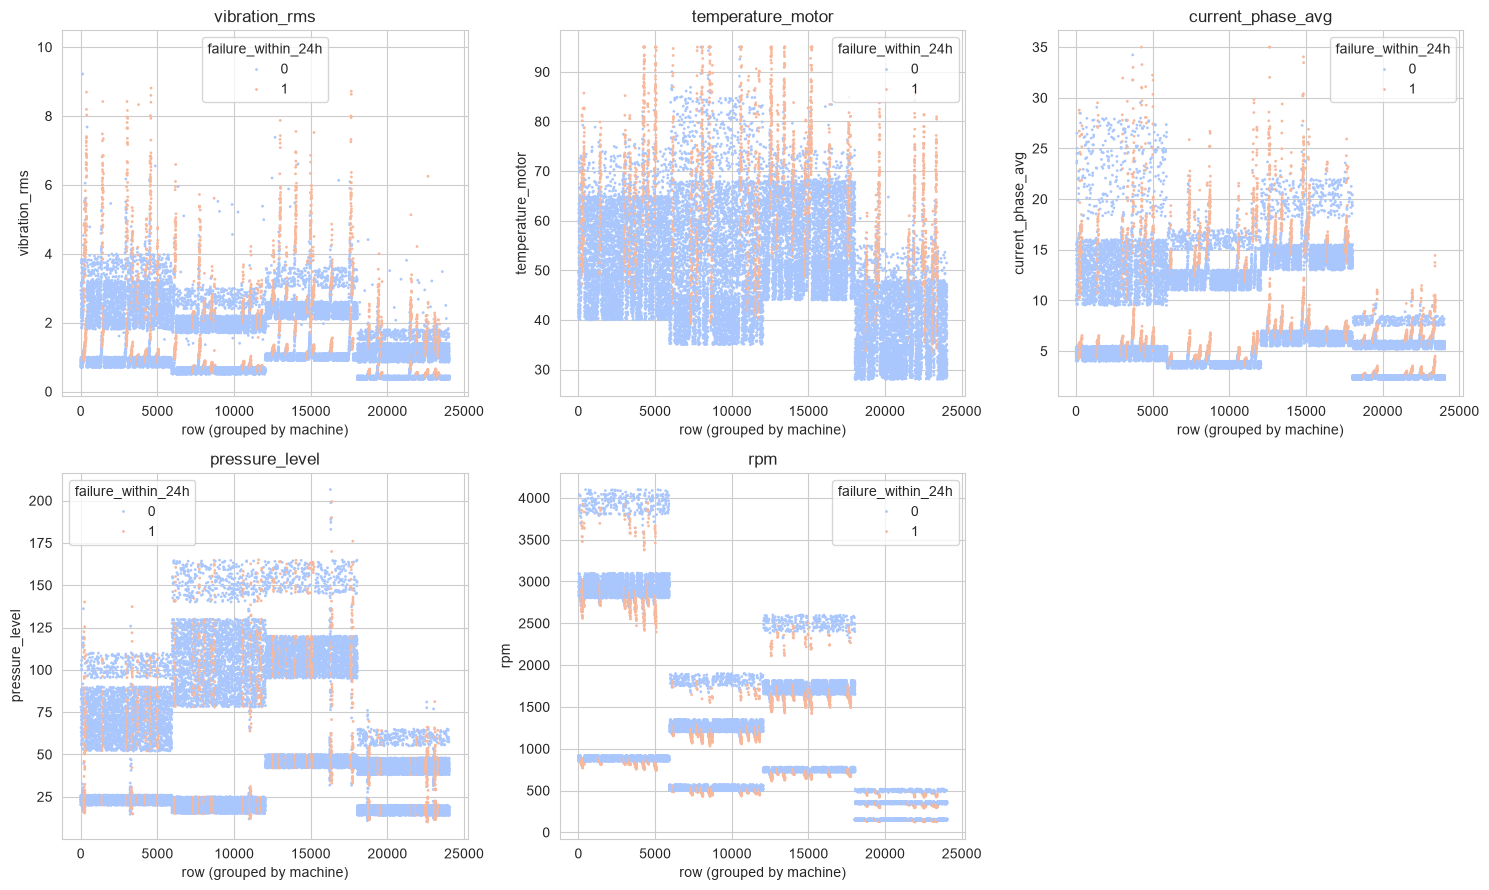

In [12]:
# FIX: the old loop called sns.scatterplot(data=df) every time and never used `col`, so it drew the
# same whole-dataframe plot 11 times. Plot each sensor on its own, coloured by failure.
sensor_cols = ["vibration_rms", "temperature_motor", "current_phase_avg", "pressure_level", "rpm"]
plt.figure(figsize=(15, 9))
for i, col in enumerate(sensor_cols):
    plt.subplot(2, 3, i + 1)
    sns.scatterplot(x=df.index, y=df[col], hue=df["failure_within_24h"], palette="coolwarm", s=4, linewidth=0)
    plt.title(col)
    plt.xlabel("row (grouped by machine)")
plt.tight_layout()
plt.show()

In [13]:
## fill in the null values with mean of the column
for col in sensor_cols:
    df[col] = df[col].fillna(df[col].mean())

# FIX: removed df.dropna(axis=1). That deletes every COLUMN that has a NaN - if it runs before the
# fill above, all five sensor columns disappear.
df.isnull().sum()

timestamp                  0
machine_id                 0
machine_type               0
vibration_rms              0
temperature_motor          0
current_phase_avg          0
pressure_level             0
rpm                        0
operating_mode             0
hours_since_maintenance    0
ambient_temp               0
rul_hours                  0
failure_within_24h         0
failure_type               0
estimated_repair_cost      0
dtype: int64

In [14]:
df.isna()

,timestamp,machine_id,machine_type,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,operating_mode,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,failure_type,estimated_repair_cost
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24037,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
24038,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
24039,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
24040,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [15]:
X=df.dropna(axis=1)

In [16]:
X

,timestamp,machine_id,machine_type,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,operating_mode,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,failure_type,estimated_repair_cost
0,2024-01-01 00:00:00,1,CNC,0.81,49.51,5.100000,23.6,860.9,idle,273.80,13.9,61.00,0,none,0
1,2024-01-01 00:03:00,1,CNC,0.75,40.58,5.300000,23.6,899.6,idle,273.85,10.2,60.95,0,none,0
2,2024-01-01 00:21:00,1,CNC,0.71,49.70,8.823829,21.3,862.7,idle,274.15,13.6,60.65,0,none,0
3,2024-01-01 00:45:00,1,CNC,0.76,43.04,4.790000,22.6,870.4,idle,274.55,13.4,60.25,0,none,0
4,2024-01-01 00:54:00,1,CNC,0.88,41.39,4.440000,22.2,881.9,idle,274.70,10.8,60.10,0,none,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24037,2024-01-14 22:17:56,20,Robotic Arm,0.98,37.18,5.270000,45.0,361.8,normal,163.43,10.2,0.50,0,none,0
24038,2024-01-14 22:41:56,20,Robotic Arm,0.45,33.90,2.210000,18.9,159.5,idle,163.83,11.0,0.50,0,none,0
24039,2024-01-14 22:58:56,20,Robotic Arm,0.40,29.15,2.290000,19.0,159.5,idle,164.12,16.2,0.50,0,none,0
24040,2024-01-14 23:23:56,20,Robotic Arm,0.45,31.47,2.450000,18.0,151.4,idle,164.53,16.7,0.50,0,none,0


In [17]:
df["machine_type"].describe()

count     24042
unique        4
top        Pump
freq       6114
Name: machine_type, dtype: object

In [18]:
df["vibration_rms"].value_counts()

vibration_rms
1.623667    1000
0.920000     241
0.430000     237
0.970000     233
0.440000     232
            ... 
6.060000       1
5.710000       1
8.720000       1
8.630000       1
6.360000       1
Name: count, Length: 657, dtype: int64

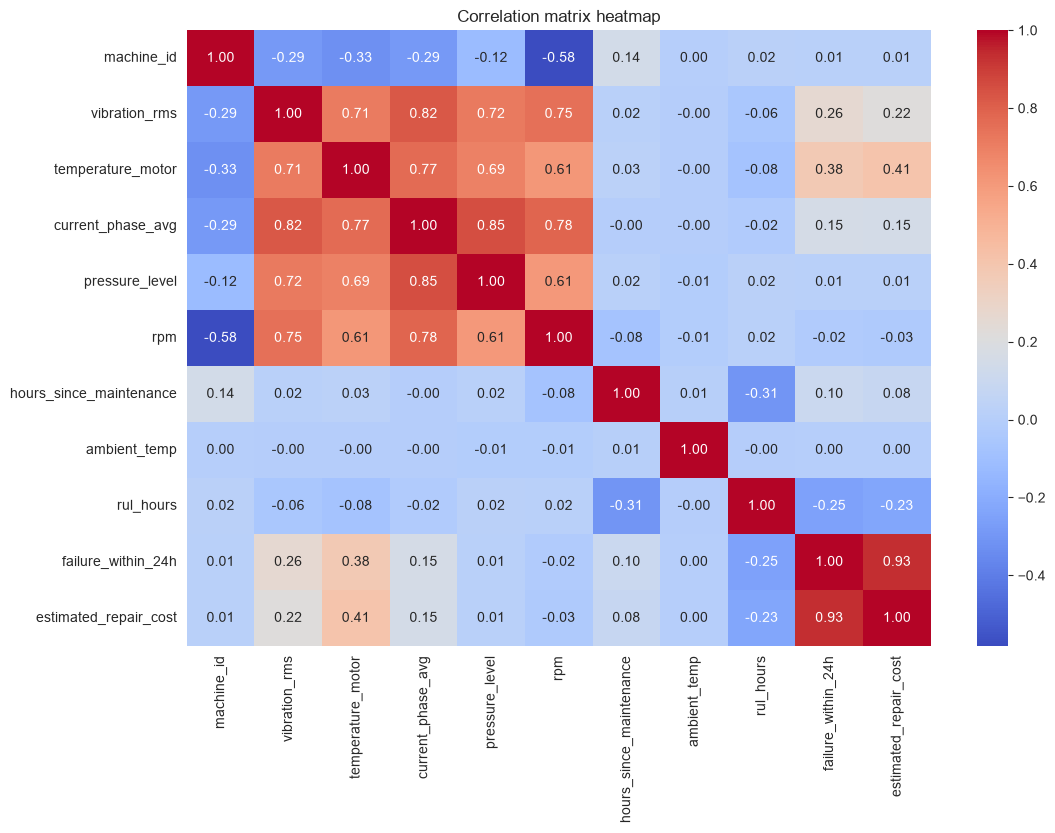

In [19]:
plt.figure(figsize=(12, 8))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation matrix heatmap')
plt.show()

In [20]:
df.columns

Index(['timestamp', 'machine_id', 'machine_type', 'vibration_rms',
       'temperature_motor', 'current_phase_avg', 'pressure_level', 'rpm',
       'operating_mode', 'hours_since_maintenance', 'ambient_temp',
       'rul_hours', 'failure_within_24h', 'failure_type',
       'estimated_repair_cost'],
      dtype='str')

In [21]:
df['timestamp']=pd.to_datetime(df['timestamp'])

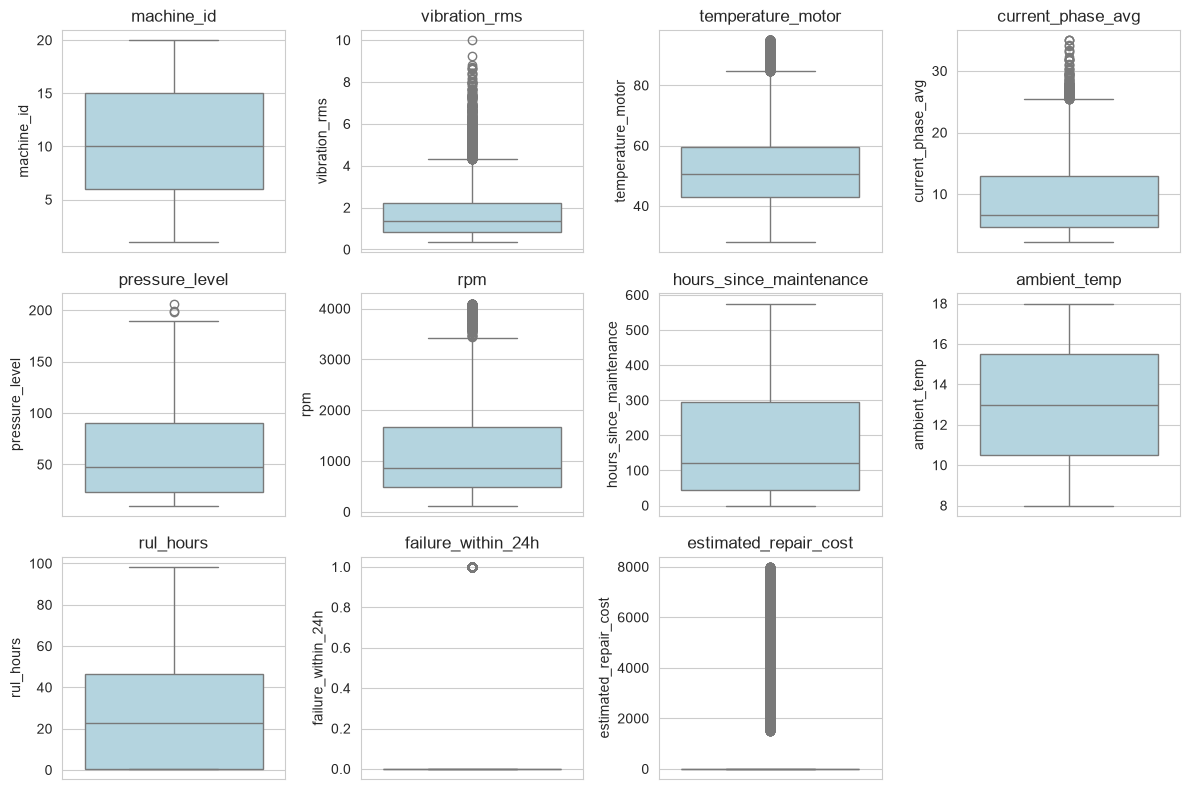

In [22]:
## Checking the outliers in the dataset
num_cols = ["machine_id", "vibration_rms", "temperature_motor", "current_phase_avg", "pressure_level", "rpm",
            "hours_since_maintenance", "ambient_temp", "rul_hours", "failure_within_24h", "estimated_repair_cost"]
plt.figure(figsize=(12, 8))
for i, col in enumerate(num_cols):
    plt.subplot(3, 4, i + 1)
    sns.boxplot(y=df[col], color="lightblue")
    plt.title(col)
plt.tight_layout()
plt.show()

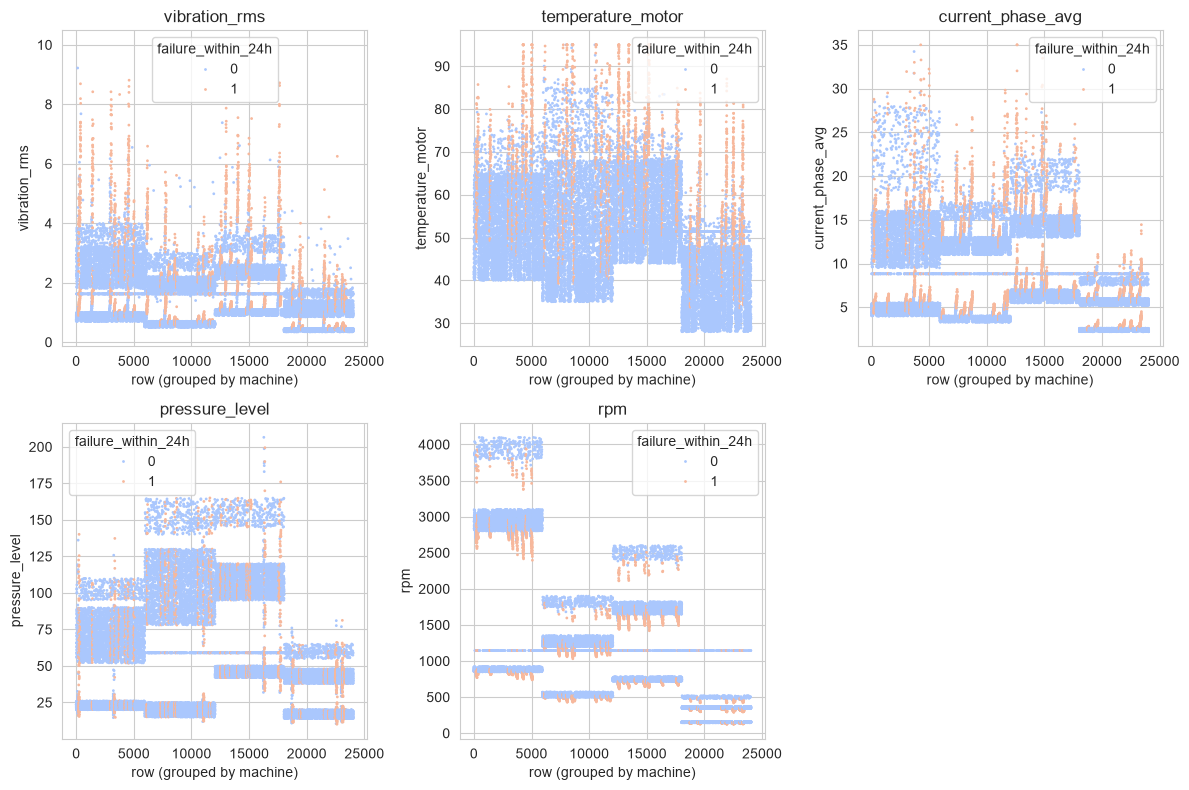

In [23]:
# FIX: the old loop called sns.scatterplot(data=df) every time and never used `col`, so it drew the
# same whole-dataframe plot 11 times. Plot each sensor on its own, coloured by failure.
sensor_cols = ["vibration_rms", "temperature_motor", "current_phase_avg", "pressure_level", "rpm"]
plt.figure(figsize=(12, 8))
for i, col in enumerate(sensor_cols):
    plt.subplot(2, 3, i + 1)
    sns.scatterplot(x=df.index, y=df[col], hue=df["failure_within_24h"], palette="coolwarm", s=4, linewidth=0)
    plt.title(col)
    plt.xlabel("row (grouped by machine)")
plt.tight_layout()
plt.show()

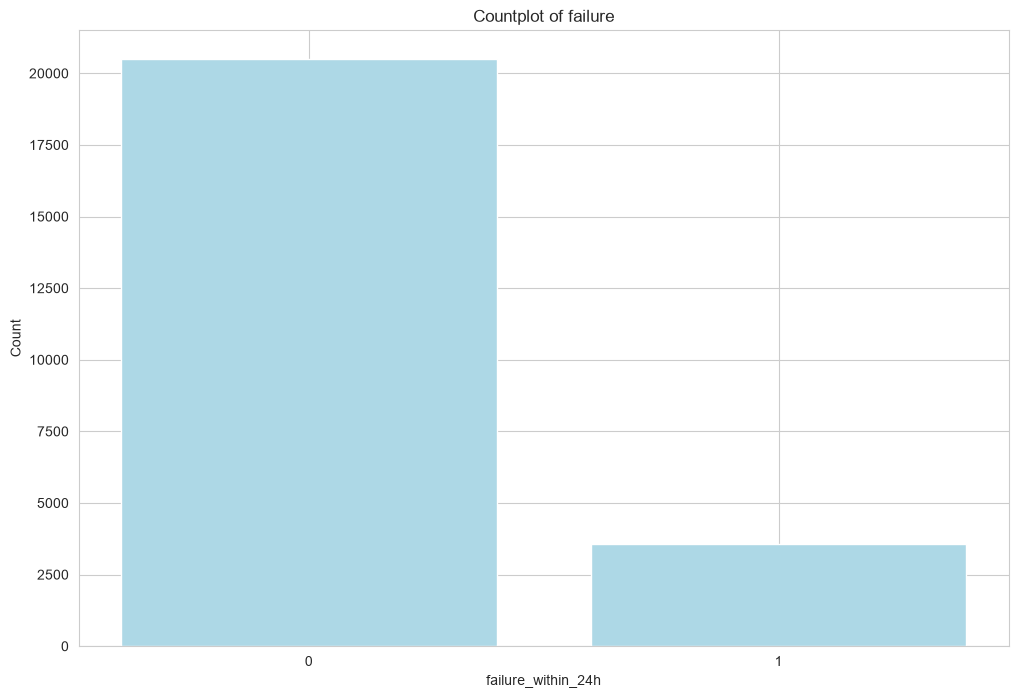

failure_within_24h
0    0.852
1    0.148
Name: proportion, dtype: float64


In [24]:
failure = df['failure_within_24h'].value_counts()
plt.figure(figsize=(12, 8))
plt.bar(failure.index.astype(str), failure, color='lightblue')
plt.title('Countplot of failure')
plt.xlabel('failure_within_24h')
plt.ylabel('Count')   # FIX: label said 'Vibration_rms'
plt.show()
print(df['failure_within_24h'].value_counts(normalize=True).round(3))

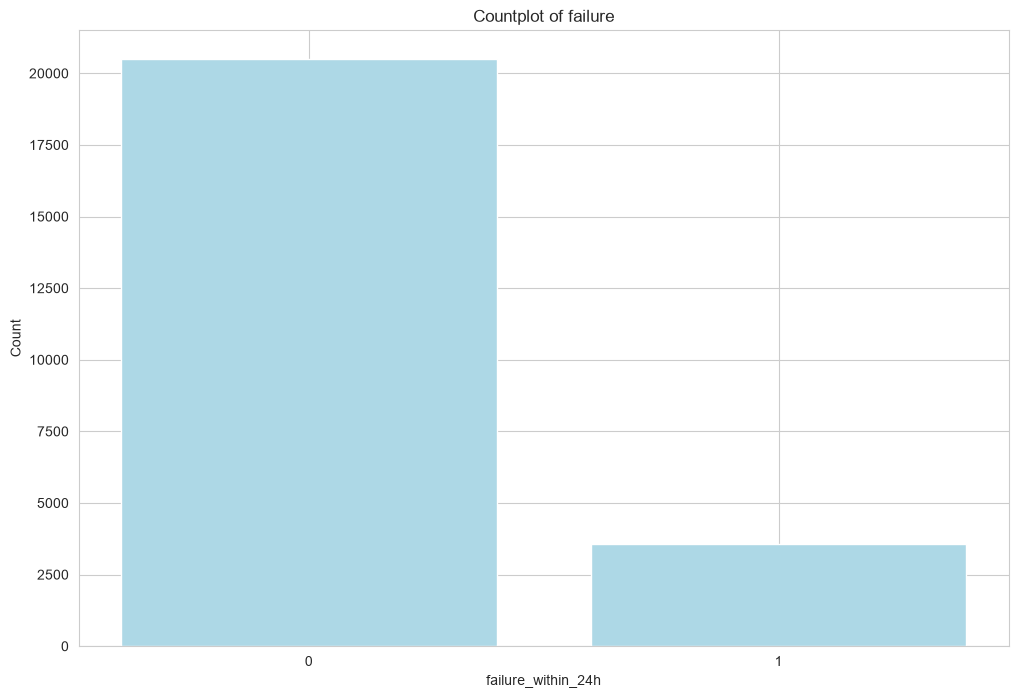

failure_within_24h
0    0.852
1    0.148
Name: proportion, dtype: float64


In [25]:
failure = df['failure_within_24h'].value_counts()
plt.figure(figsize=(12, 8))
plt.bar(failure.index.astype(str), failure, color='lightblue')
plt.title('Countplot of failure')
plt.xlabel('failure_within_24h')
plt.ylabel('Count')   # FIX: label said 'Vibration_rms'
plt.show()
print(df['failure_within_24h'].value_counts(normalize=True).round(3))

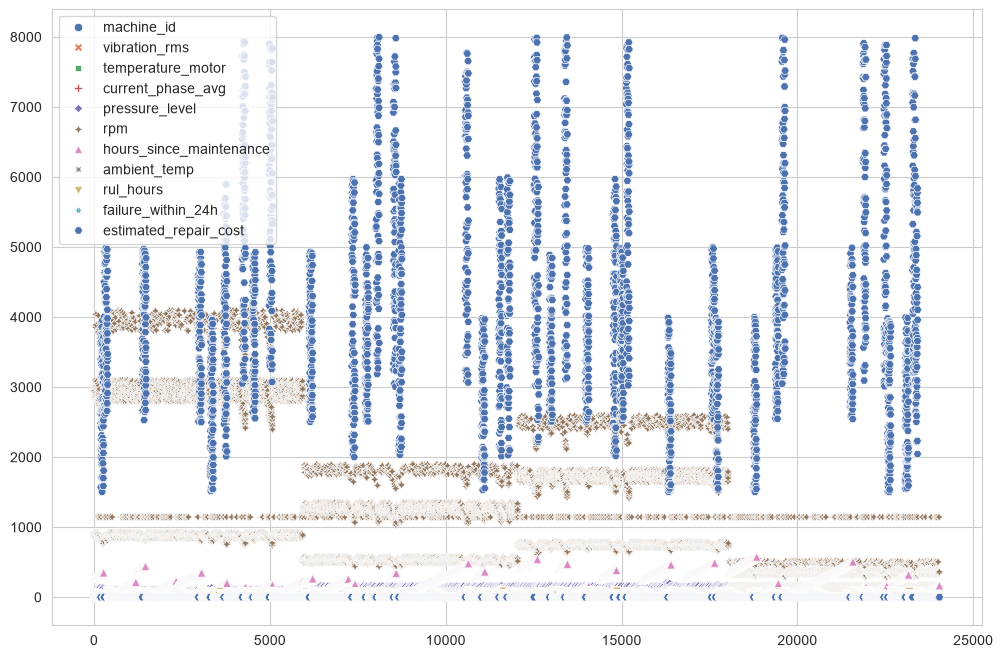

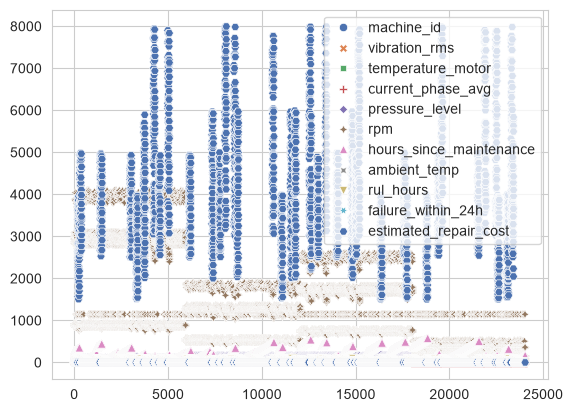

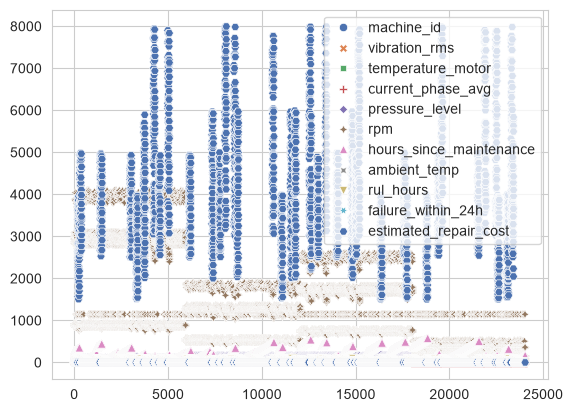

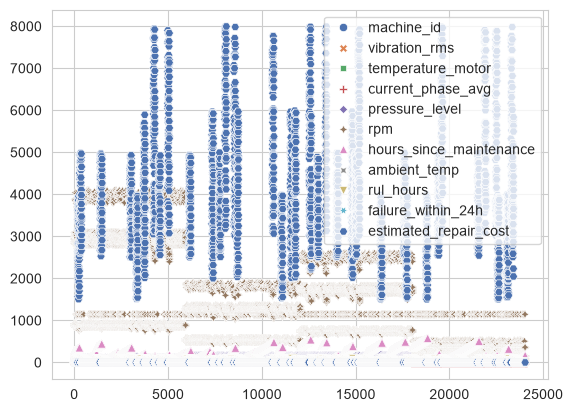

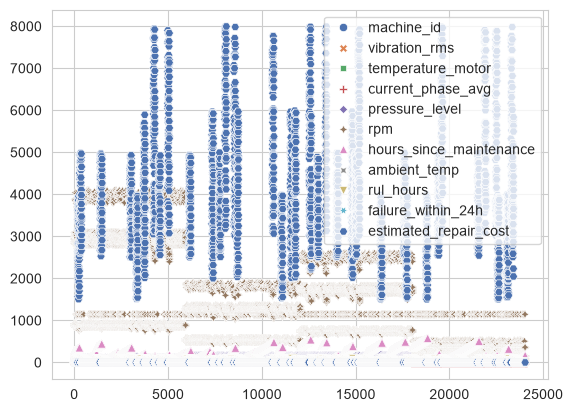

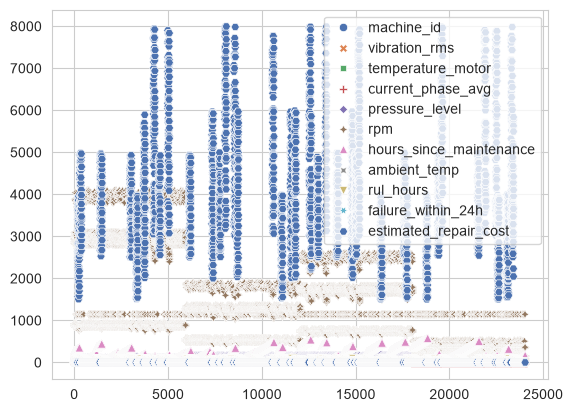

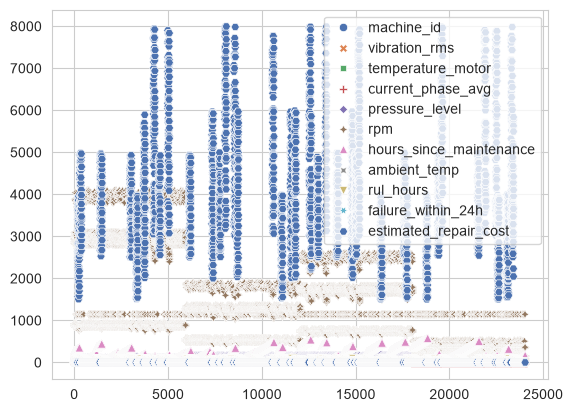

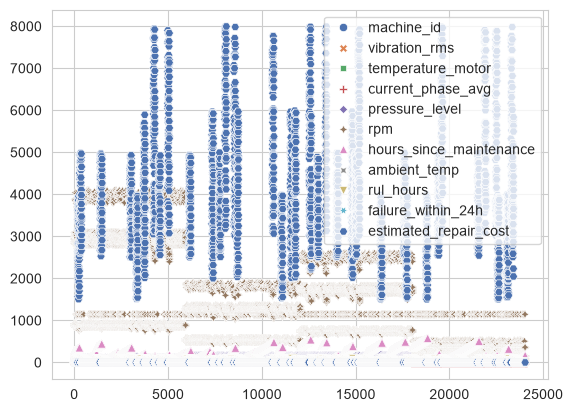

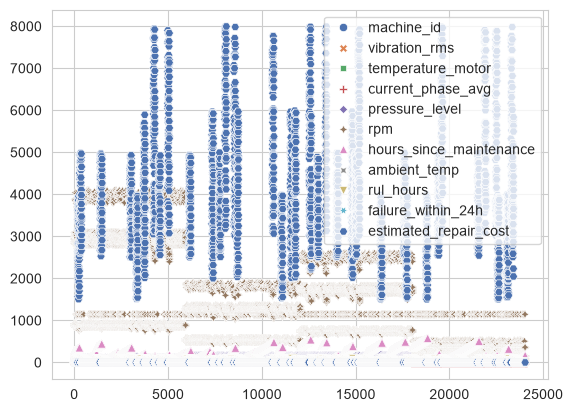

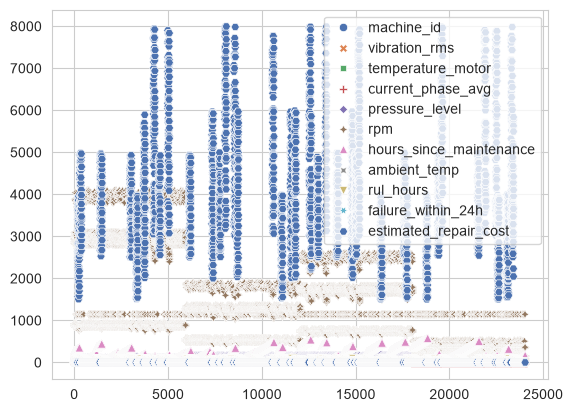

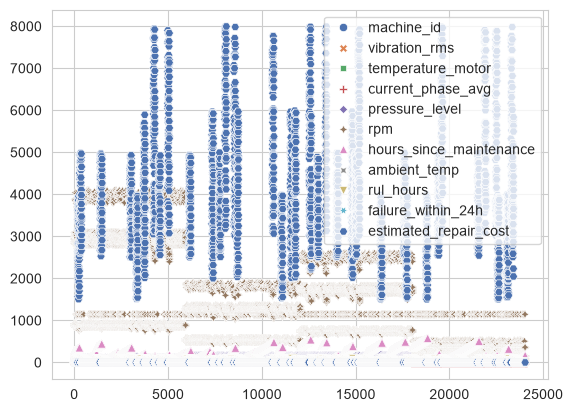

In [26]:
plt.figure(figsize=(12,8))
for i, col in enumerate(["machine_id","vibration_rms","temperature_motor","current_phase_avg","pressure_level","rpm","hours_since_maintenance","ambient_temp","rul_hours","failure_within_24h","estimated_repair_cost"]):
    sns.scatterplot(data=df,palette='deep')
    plt.show()


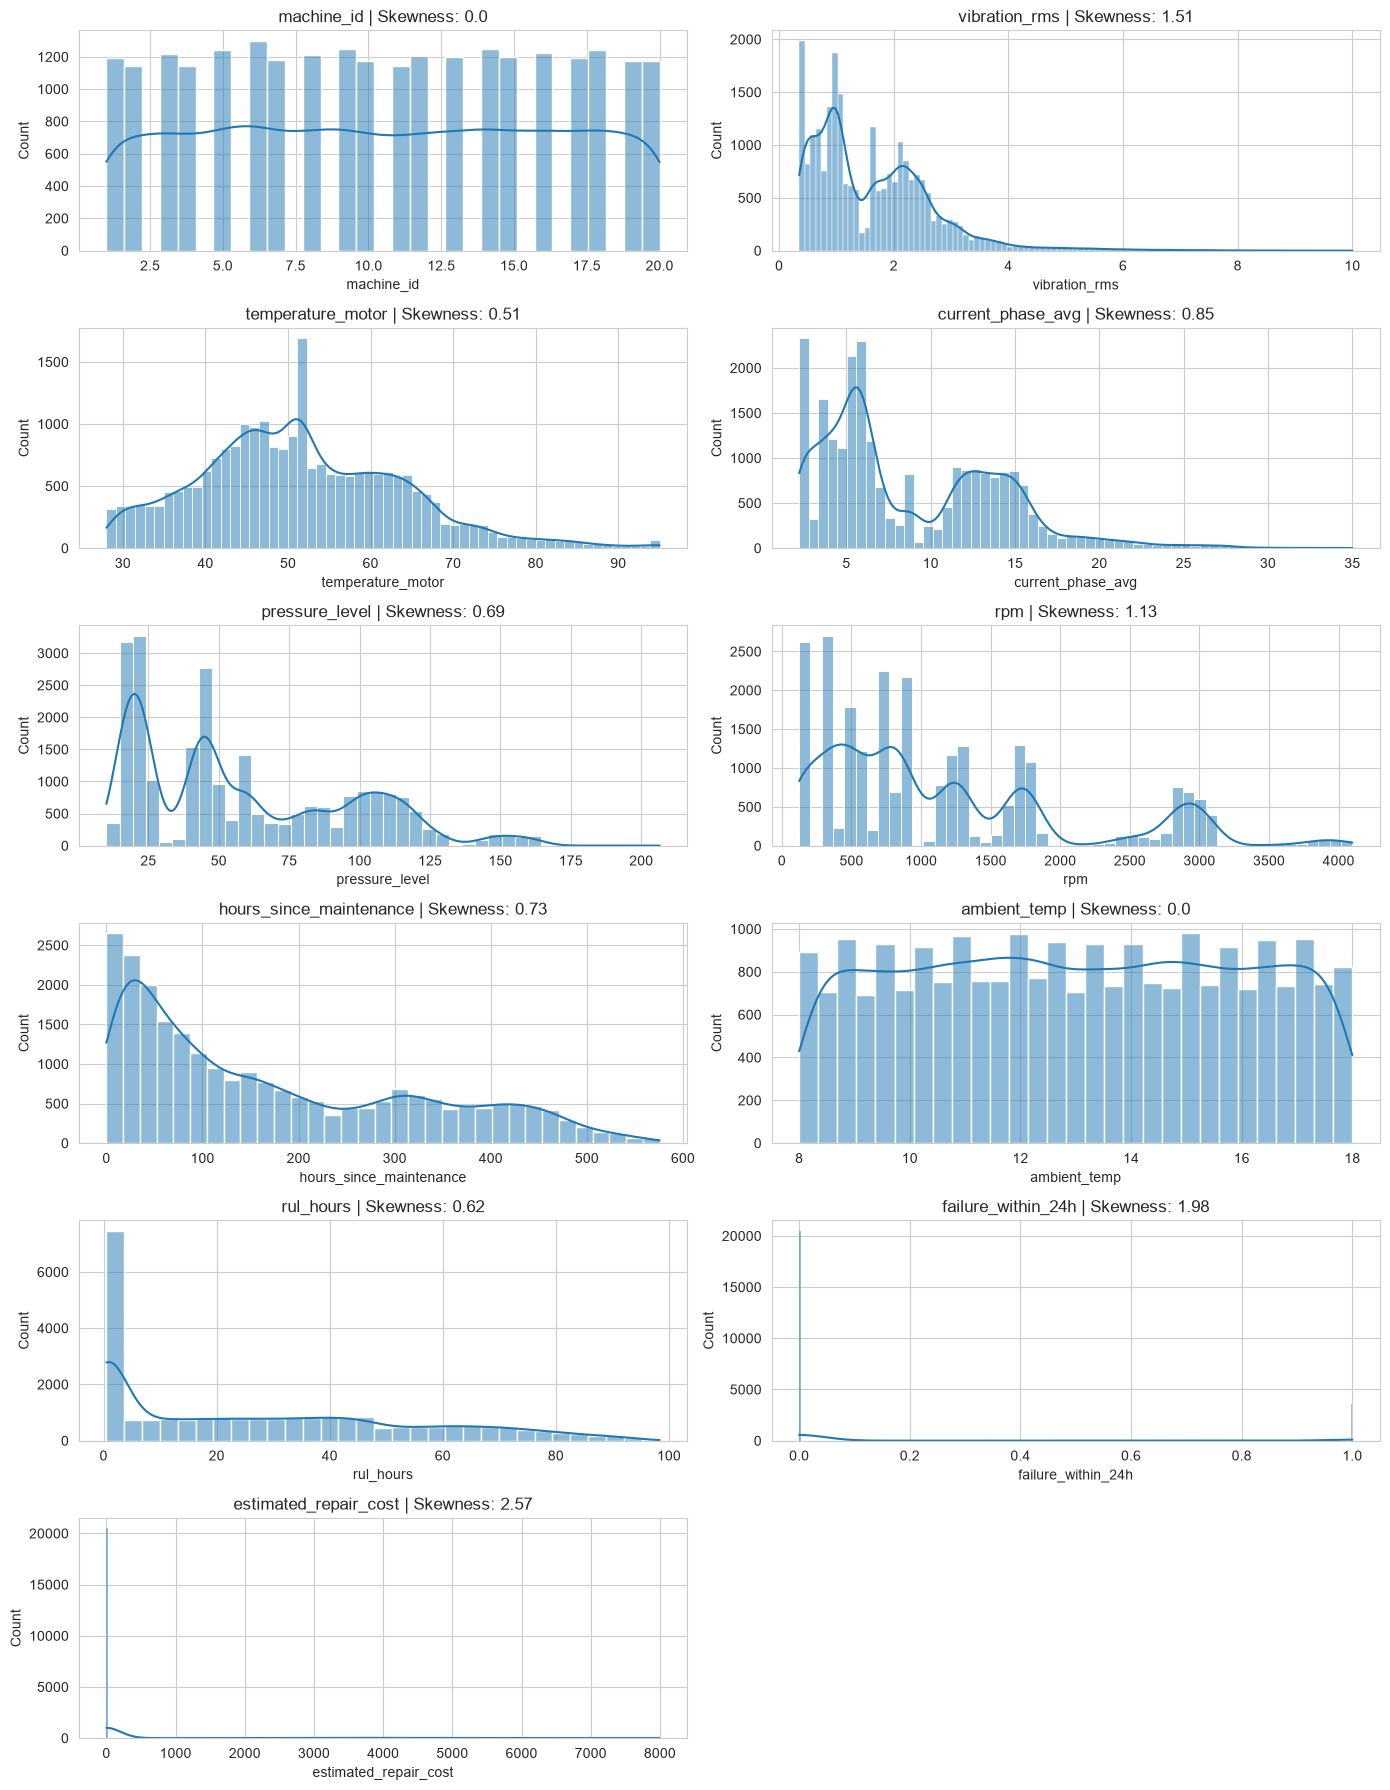

In [27]:
numerical_columns = df.select_dtypes(include='number').columns
n_rows = int(np.ceil(len(numerical_columns) / 2))
plt.figure(figsize=(14, n_rows * 3))
for idx, feature in enumerate(numerical_columns, 1):
    plt.subplot(n_rows, 2, idx)
    sns.histplot(df[feature], kde=True)
    plt.title(f"{feature} | Skewness: {round(df[feature].skew(), 2)}")
# FIX: tight_layout()/show() were inside the loop, so each plot popped out on its own
plt.tight_layout()
plt.show()

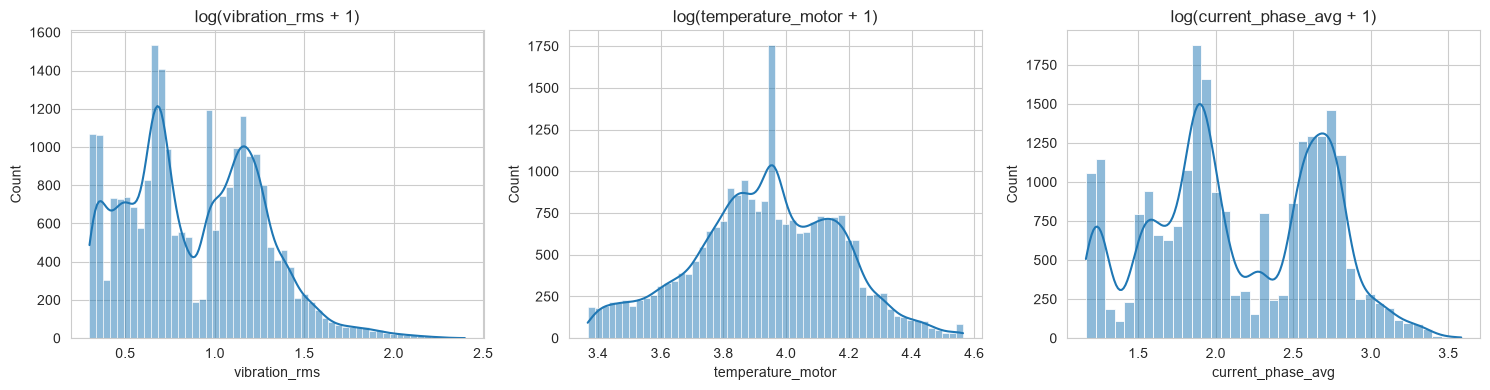

In [28]:
# Log transformation of the skewed sensors (viewing only - tree models don't need it)
# FIX: sns.distplot is deprecated / removed in newer seaborn -> sns.histplot(kde=True)
plt.figure(figsize=(15, 4))
for i, col in enumerate(["vibration_rms", "temperature_motor", "current_phase_avg"]):
    plt.subplot(1, 3, i + 1)
    sns.histplot(np.log1p(df[col]), kde=True)
    plt.title(f"log({col} + 1)")
plt.tight_layout()
plt.show()

<Axes: xlabel='vibration_rmslog', ylabel='Density'>

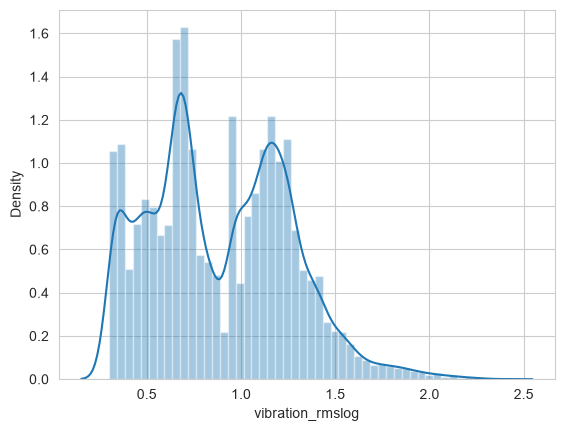

In [29]:
# Apply Log transformation
df["vibration_rmslog"]=np.log(df["vibration_rms"] + 1)
sns.distplot(df["vibration_rmslog"])

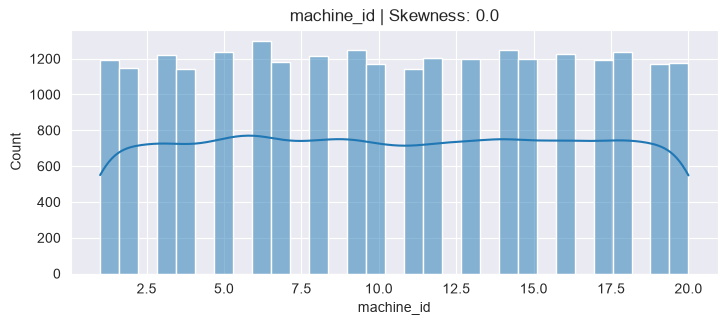

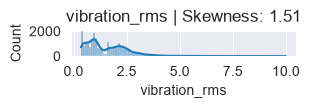

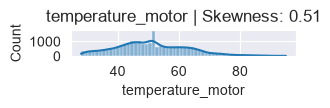

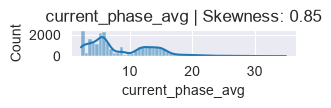

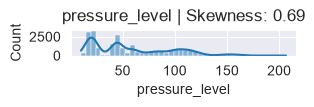

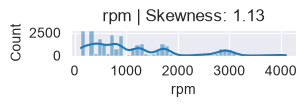

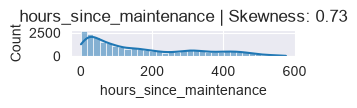

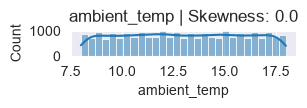

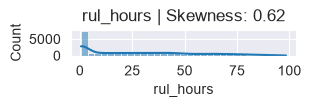

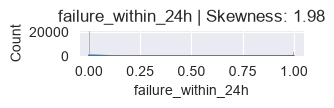

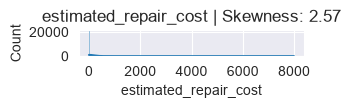

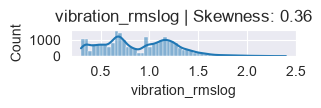

In [30]:
sns.set_style('darkgrid')
numerical_columns=df.select_dtypes(include=['int64','float64']).columns
plt.figure(figsize=(14,len(numerical_columns)*3))
for idx, feature in enumerate(numerical_columns, 1):
    plt.subplot(len(numerical_columns),2,idx)
    sns.histplot(df[feature],kde=True)
    plt.title(f"{feature} | Skewness: {round(df[feature].skew(),2)}")
    plt.tight_layout()
    plt.show()

<Axes: xlabel='temperature_motor_log', ylabel='Density'>

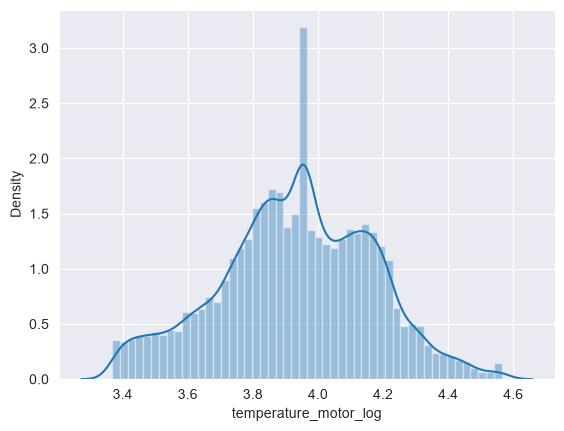

In [31]:
df["temperature_motor_log"]=np.log(df["temperature_motor"] + 1)
sns.distplot(df["temperature_motor_log"])

<Axes: xlabel='current_phase_avg_log', ylabel='Density'>

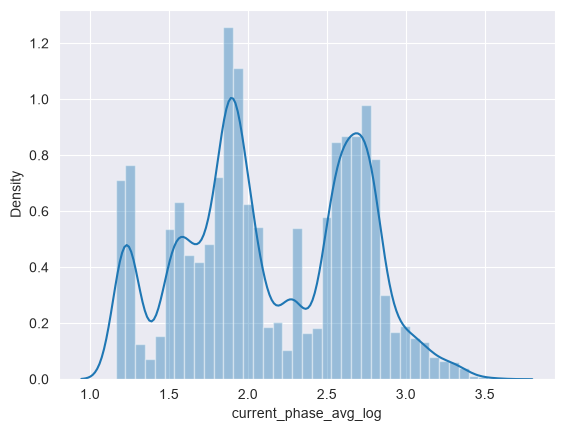

In [32]:
df["current_phase_avg_log"]=np.log(df["current_phase_avg"] + 1)
sns.distplot(df["current_phase_avg_log"])

In [33]:
print(pd.crosstab(df['failure_type'], df['failure_within_24h']), "\n")
print(df.groupby('failure_within_24h')[['estimated_repair_cost', 'rul_hours']].describe().T)

failure_within_24h      0     1
failure_type                   
bearing                 0  1117
electrical              0   655
hydraulic               0   728
motor_overheat          0  1060
none                20482     0 

failure_within_24h                      0            1
estimated_repair_cost count  20482.000000  3560.000000
                      mean       0.000000  4111.925843
                      std        0.000000  1474.476669
                      min        0.000000  1502.000000
                      25%        0.000000  3049.000000
                      50%        0.000000  3842.000000
                      75%        0.000000  4897.500000
                      max        0.000000  7995.000000
rul_hours             count  20482.000000  3560.000000
                      mean      30.598986    11.780882
                      std       27.511557     6.951295
                      min        0.500000     0.500000
                      25%        0.500000     5.690000
    

In [34]:
# FIX: LabelEncoder on 'timestamp' turned every date into a meaningless ID number.
# Take useful parts of the time instead.
from sklearn.preprocessing import LabelEncoder
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['hour'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.dayofweek

# One-hot encode the text categories (LabelEncoder implied a fake order, e.g. CNC < Compressor < Pump)
df_model = pd.get_dummies(df, columns=['machine_type', 'operating_mode'], dtype=int)

# Outcome columns (leakage) and identifiers are never inputs
target_cols = ['failure_within_24h', 'failure_type', 'estimated_repair_cost', 'rul_hours']
drop_cols = target_cols + ['timestamp', 'machine_id']
FEATURES = [c for c in df_model.columns if c not in drop_cols]

X = df_model[FEATURES]
y = df_model['failure_within_24h']

# failure_type as numbers 0..k-1 (needed by XGBoost and for plotting)
le_type = LabelEncoder()
y_type = le_type.fit_transform(df_model['failure_type'])

print(len(FEATURES), 'features:', FEATURES)

19 features: ['vibration_rms', 'temperature_motor', 'current_phase_avg', 'pressure_level', 'rpm', 'hours_since_maintenance', 'ambient_temp', 'vibration_rmslog', 'temperature_motor_log', 'current_phase_avg_log', 'hour', 'day_of_week', 'machine_type_CNC', 'machine_type_Compressor', 'machine_type_Pump', 'machine_type_Robotic Arm', 'operating_mode_idle', 'operating_mode_normal', 'operating_mode_peak']


In [36]:
#Encoding: Label encoding, one hot encoding

from sklearn.preprocessing import LabelEncoder
cols=['timestamp','machine_type','operating_mode','failure_type']
le=LabelEncoder()
for col in cols:
    df[col]=le.fit_transform(df[col])

In [37]:
# One split shared by all classifiers so their scores are comparable.
# stratify=y keeps the ~15% failure rate the same in train and test.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# FIX: fit the scaler on TRAIN only, then transform test (some cells used fit_transform on X_test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(X_train.shape, X_test.shape)

(19233, 19) (4809, 19)


In [38]:
results = {}

def evaluate(name, model, X_tr, X_te):
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)
    # FIX: ROC-AUC needs probabilities/scores, not 0/1 predictions
    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_te)[:, 1]
    else:
        y_score = model.decision_function(X_te)
    results[name] = {
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'roc_auc': roc_auc_score(y_test, y_score),
    }
    # FIX: the old print said 'Accuracy' but printed precision, and '{acc:.4f}' was missing the f
    print(f'===== {name} =====')
    for metric, value in results[name].items():
        print(f'{metric:10s}: {value:.4f}')
    print('\nConfusion matrix (rows = actual, columns = predicted):')
    print(confusion_matrix(y_test, y_pred))
    print('\nClassification report:')
    print(classification_report(y_test, y_pred))
    return model

print('Baseline - always predict "no failure", accuracy:', round(1 - y_test.mean(), 4))

Baseline - always predict "no failure", accuracy: 0.8519


In [ ]:
#Classification models

In [39]:
# Logistic Regression
# FIX: the old cell trained on make_classification() fake data
model1 = evaluate('Logistic Regression', LogisticRegression(max_iter=1000, random_state=42),
                  X_train_scaled, X_test_scaled)

===== Logistic Regression =====
accuracy  : 0.9316
precision : 0.8144
recall    : 0.6966
f1        : 0.7509
roc_auc   : 0.9604

Confusion matrix (rows = actual, columns = predicted):
[[3984  113]
 [ 216  496]]

Classification report:
              precision    recall  f1-score   support

           0       0.95      0.97      0.96      4097
           1       0.81      0.70      0.75       712

    accuracy                           0.93      4809
   macro avg       0.88      0.83      0.86      4809
weighted avg       0.93      0.93      0.93      4809



In [40]:
# FIX: 'model1' didn't exist before (NameError). The pipeline re-fits the scaler inside each fold.
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
score = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                        X_train, y_train, cv=cv, scoring='f1')
print('Cross validation F1 of Logistic Regression:', score.round(4), '| mean:', round(np.mean(score) * 100, 2))

Cross validation F1 of Logistic Regression: [0.7378 0.7537 0.7445 0.773  0.7476] | mean: 75.13


Best parameters: {'C': 10, 'solver': 'lbfgs'}


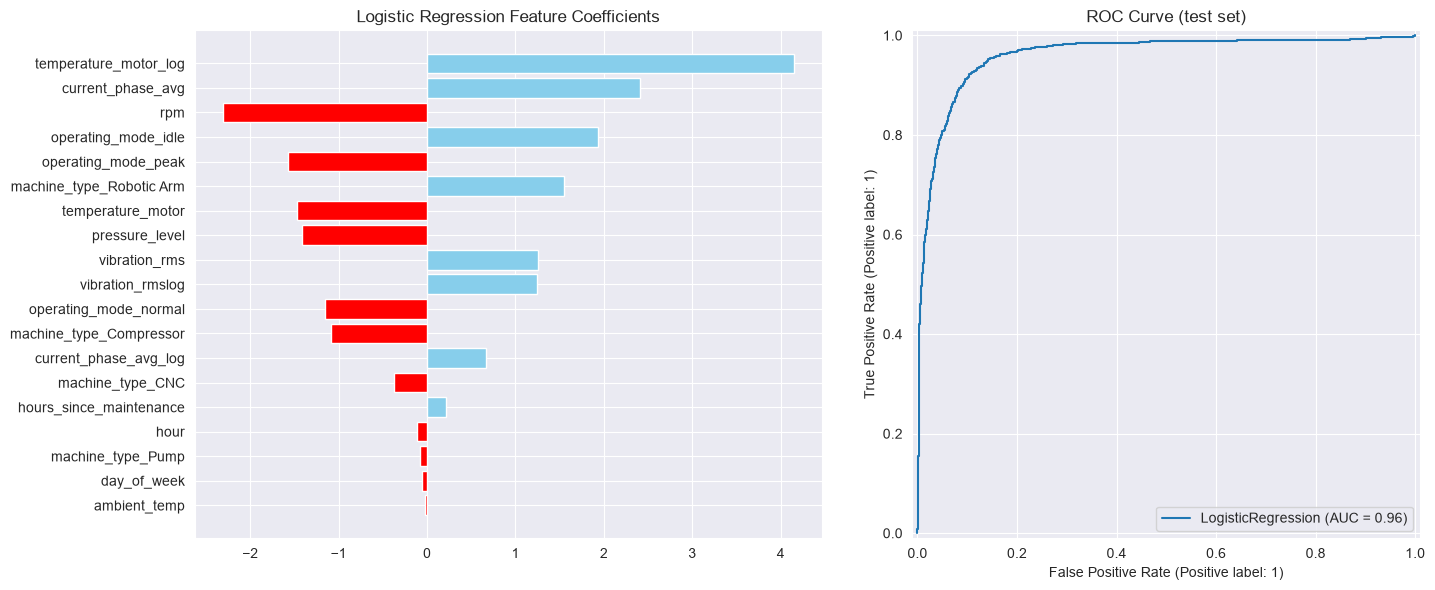

In [41]:
# Grid search + coefficients + ROC curve
# (moved from the old "LogisticRegression for estimated repair cost" cell: logistic regression is a
#  classifier, so it can't predict a money amount - it belongs here with failure_within_24h)
param_grid = {'C': [0.01, 0.1, 1, 10, 100], 'solver': ['lbfgs', 'liblinear']}
grid_search = GridSearchCV(LogisticRegression(max_iter=1000), param_grid, cv=5, scoring='f1')
grid_search.fit(X_train_scaled, y_train)
best_model = grid_search.best_estimator_
print('Best parameters:', grid_search.best_params_)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
coefficients = best_model.coef_[0]
order = np.argsort(np.abs(coefficients))
axes[0].barh(np.array(FEATURES)[order], coefficients[order],
             color=['red' if c < 0 else 'skyblue' for c in coefficients[order]])
axes[0].set_title('Logistic Regression Feature Coefficients')
# FIX: ROC curve on the TEST set (it was drawn on the training data)
RocCurveDisplay.from_estimator(best_model, X_test_scaled, y_test, ax=axes[1])
axes[1].set_title('ROC Curve (test set)')
plt.tight_layout()
plt.show()

In [42]:
# Support Vector Machine (RBF kernel) - can take a minute on ~19k rows
# FIX: the old cell trained on make_classification() fake data
model11 = evaluate('SVM (RBF)', SVC(kernel='rbf', C=1.0, gamma='scale'), X_train_scaled, X_test_scaled)

===== SVM (RBF) =====
accuracy  : 0.9474
precision : 0.8441
recall    : 0.7907
f1        : 0.8165
roc_auc   : 0.9751

Confusion matrix (rows = actual, columns = predicted):
[[3993  104]
 [ 149  563]]

Classification report:
              precision    recall  f1-score   support

           0       0.96      0.97      0.97      4097
           1       0.84      0.79      0.82       712

    accuracy                           0.95      4809
   macro avg       0.90      0.88      0.89      4809
weighted avg       0.95      0.95      0.95      4809



In [43]:
df["machine_type"].unique()

array([0, 2, 1, 3])

In [44]:
df.duplicated().sum()

np.int64(0)

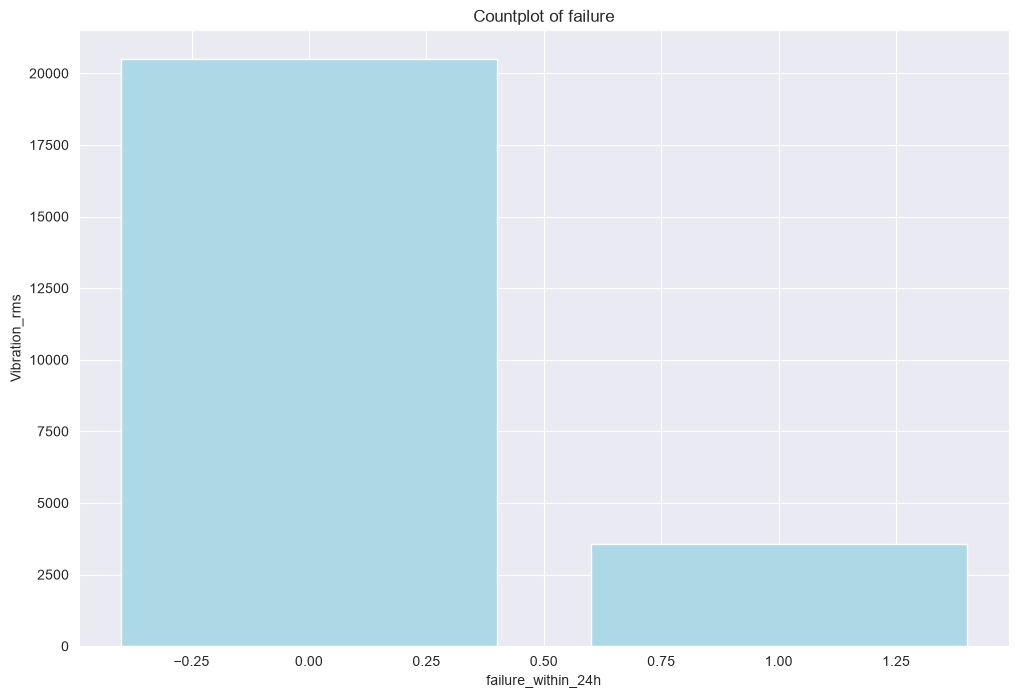

In [45]:

failure=df['failure_within_24h'].value_counts()
plt.figure(figsize=(12,8))
plt.bar(failure.index,failure,color='lightblue')
plt.title('Countplot of failure')
plt.xlabel('failure_within_24h')
plt.ylabel('Vibration_rms')
plt.show()



In [46]:
df=df.dropna().reset_index(drop=True)
df


,timestamp,machine_id,machine_type,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,operating_mode,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,failure_type,estimated_repair_cost,vibration_rmslog,temperature_motor_log,current_phase_avg_log,hour,day_of_week
0,0,1,0,0.81,49.51,5.100000,23.6,860.9,0,273.80,13.9,61.00,0,4,0,0.593327,3.922171,1.808289,0,0
1,2,1,0,0.75,40.58,5.300000,23.6,899.6,0,273.85,10.2,60.95,0,4,0,0.559616,3.727619,1.840550,0,0
2,15,1,0,0.71,49.70,8.823829,21.3,862.7,0,274.15,13.6,60.65,0,4,0,0.536493,3.925926,2.284811,0,0
3,31,1,0,0.76,43.04,4.790000,22.6,870.4,0,274.55,13.4,60.25,0,4,0,0.565314,3.785098,1.756132,0,0
4,37,1,0,0.88,41.39,4.440000,22.2,881.9,0,274.70,10.8,60.10,0,4,0,0.631272,3.746912,1.693779,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24037,21060,20,3,0.98,37.18,5.270000,45.0,361.8,1,163.43,10.2,0.50,0,4,0,0.683097,3.642312,1.835776,22,6
24038,21091,20,3,0.45,33.90,2.210000,18.9,159.5,0,163.83,11.0,0.50,0,4,0,0.371564,3.552487,1.166271,22,6
24039,21109,20,3,0.40,29.15,2.290000,19.0,159.5,0,164.12,16.2,0.50,0,4,0,0.336472,3.406185,1.190888,22,6
24040,21136,20,3,0.45,31.47,2.450000,18.0,151.4,0,164.53,16.7,0.50,0,4,0,0.371564,3.480317,1.238374,23,6


In [47]:
df.columns

Index(['timestamp', 'machine_id', 'machine_type', 'vibration_rms',
       'temperature_motor', 'current_phase_avg', 'pressure_level', 'rpm',
       'operating_mode', 'hours_since_maintenance', 'ambient_temp',
       'rul_hours', 'failure_within_24h', 'failure_type',
       'estimated_repair_cost', 'vibration_rmslog', 'temperature_motor_log',
       'current_phase_avg_log', 'hour', 'day_of_week'],
      dtype='str')

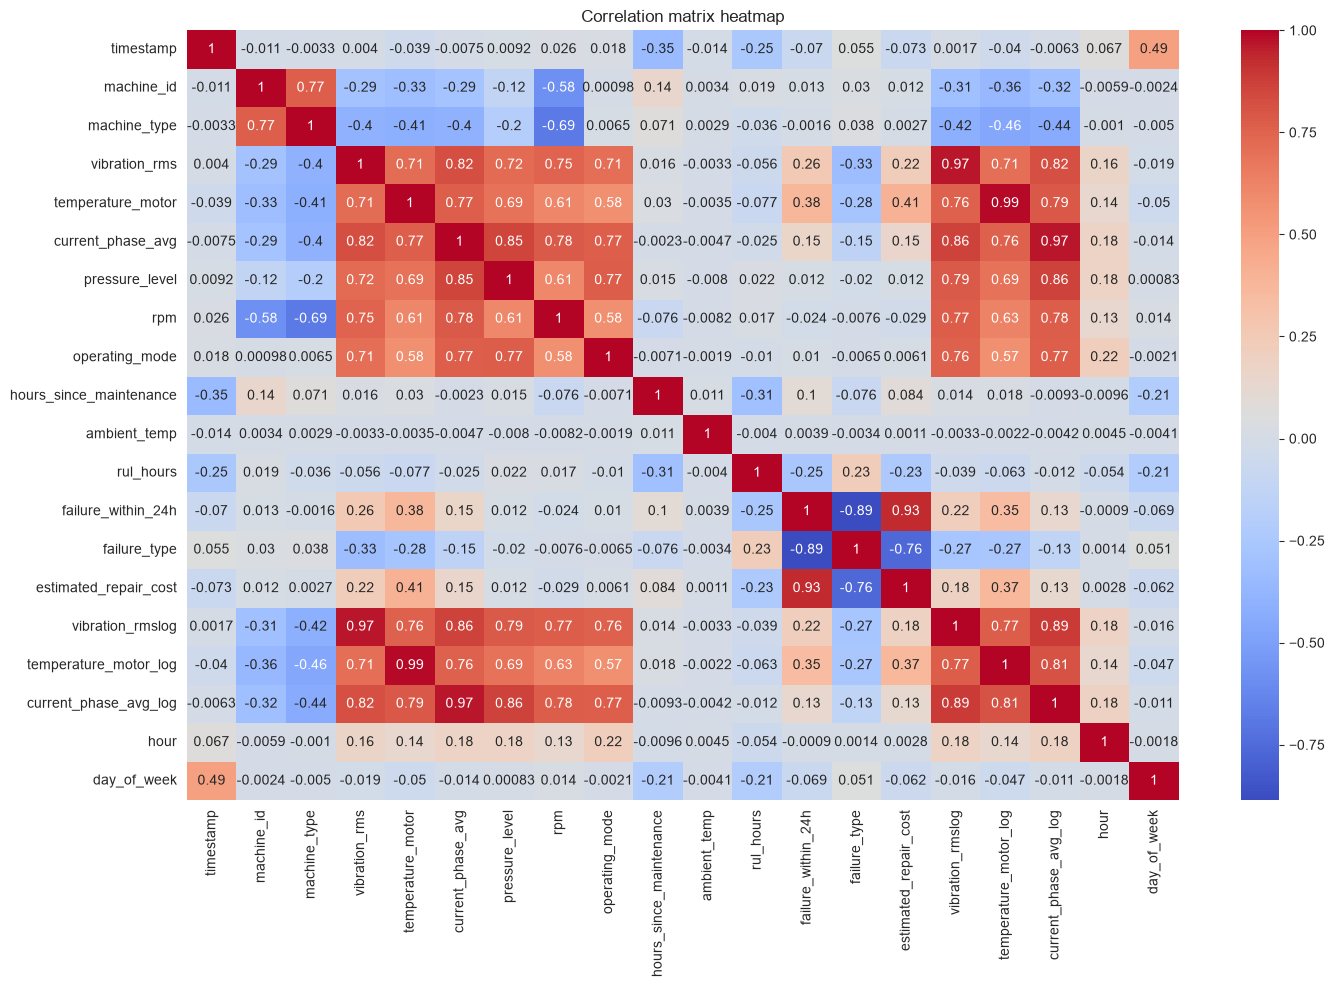

In [303]:
plt.figure(figsize=(16,10))
numerical_df = df.select_dtypes(include=[np.number])
corr_matrix=numerical_df.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation matrix heatmap')
plt.show()

In [48]:
df.query("vibration_rms > 0.5")

,timestamp,machine_id,machine_type,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,operating_mode,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,failure_type,estimated_repair_cost,vibration_rmslog,temperature_motor_log,current_phase_avg_log,hour,day_of_week
0,0,1,0,0.810000,49.51,5.100000,23.6,860.900000,0,273.80,13.9,61.00,0,4,0,0.593327,3.922171,1.808289,0,0
1,2,1,0,0.750000,40.58,5.300000,23.6,899.600000,0,273.85,10.2,60.95,0,4,0,0.559616,3.727619,1.840550,0,0
2,15,1,0,0.710000,49.70,8.823829,21.3,862.700000,0,274.15,13.6,60.65,0,4,0,0.536493,3.925926,2.284811,0,0
3,31,1,0,0.760000,43.04,4.790000,22.6,870.400000,0,274.55,13.4,60.25,0,4,0,0.565314,3.785098,1.756132,0,0
4,37,1,0,0.880000,41.39,4.440000,22.2,881.900000,0,274.70,10.8,60.10,0,4,0,0.631272,3.746912,1.693779,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24031,20936,20,3,1.623667,41.19,5.750000,47.6,367.900000,1,161.87,10.0,0.50,0,4,0,0.964573,3.742183,1.909543,20,6
24032,20964,20,3,1.380000,45.91,5.760000,40.1,345.500000,1,162.27,16.4,0.50,0,4,0,0.867100,3.848231,1.911023,21,6
24033,20985,20,3,1.040000,46.71,5.400000,40.1,1144.849317,1,162.48,13.2,0.50,0,4,0,0.712950,3.865141,1.856298,21,6
24035,21023,20,3,1.623667,28.84,2.240000,14.9,156.400000,0,162.95,14.6,0.50,0,4,0,0.964573,3.395850,1.175573,21,6


In [49]:
categorical_cols = ["timestamp", "machine_id", "machine_type", "vibration_rms", "temperature_motor", "current_phase_avg", "pressure_level","rpm", "hours_since_maintenance", "ambient_temp","rul_hours", "failure_within_24h", "estimated_repair_cost"]

In [50]:
corr=df[["machine_id","vibration_rms","temperature_motor","current_phase_avg","pressure_level","rpm","hours_since_maintenance","ambient_temp","rul_hours","failure_within_24h","estimated_repair_cost"]].corr()

In [51]:
corr

,machine_id,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,estimated_repair_cost
machine_id,1.000000,-0.290327,-0.326012,-0.287715,-0.120485,-0.582279,0.143779,0.003429,0.018926,0.012657,0.012059
vibration_rms,-0.290327,1.000000,0.714354,0.824254,0.720573,0.752139,0.016232,-0.003284,-0.056014,0.258622,0.219092
temperature_motor,-0.326012,0.714354,1.000000,0.765345,0.692640,0.612798,0.029596,-0.003529,-0.076622,0.379009,0.406821
current_phase_avg,-0.287715,0.824254,0.765345,1.000000,0.853105,0.784197,-0.002255,-0.004682,-0.024566,0.154147,0.150964
pressure_level,-0.120485,0.720573,0.692640,0.853105,1.000000,0.606105,0.015096,-0.007968,0.021606,0.012399,0.012275
rpm,-0.582279,0.752139,0.612798,0.784197,0.606105,1.000000,-0.076174,-0.008201,0.016732,-0.023904,-0.029461
hours_since_maintenance,0.143779,0.016232,0.029596,-0.002255,0.015096,-0.076174,1.000000,0.010680,-0.306790,0.099519,0.083766
ambient_temp,0.003429,-0.003284,-0.003529,-0.004682,-0.007968,-0.008201,0.010680,1.000000,-0.004021,0.003907,0.001148
rul_hours,0.018926,-0.056014,-0.076622,-0.024566,0.021606,0.016732,-0.306790,-0.004021,1.000000,-0.253235,-0.234846
failure_within_24h,0.012657,0.258622,0.379009,0.154147,0.012399,-0.023904,0.099519,0.003907,-0.253235,1.000000,0.932144


In [52]:
df.head()

,timestamp,machine_id,machine_type,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,operating_mode,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,failure_type,estimated_repair_cost,vibration_rmslog,temperature_motor_log,current_phase_avg_log,hour,day_of_week
0,0,1,0,0.81,49.51,5.100000,23.6,860.9,0,273.80,13.9,61.00,0,4,0,0.593327,3.922171,1.808289,0,0
1,2,1,0,0.75,40.58,5.300000,23.6,899.6,0,273.85,10.2,60.95,0,4,0,0.559616,3.727619,1.840550,0,0
2,15,1,0,0.71,49.70,8.823829,21.3,862.7,0,274.15,13.6,60.65,0,4,0,0.536493,3.925926,2.284811,0,0
3,31,1,0,0.76,43.04,4.790000,22.6,870.4,0,274.55,13.4,60.25,0,4,0,0.565314,3.785098,1.756132,0,0
4,37,1,0,0.88,41.39,4.440000,22.2,881.9,0,274.70,10.8,60.10,0,4,0,0.631272,3.746912,1.693779,0,0


In [53]:
df.dtypes

timestamp                    int64
machine_id                   int64
machine_type                 int64
vibration_rms              float64
temperature_motor          float64
current_phase_avg          float64
pressure_level             float64
rpm                        float64
operating_mode               int64
hours_since_maintenance    float64
ambient_temp               float64
rul_hours                  float64
failure_within_24h           int64
failure_type                 int64
estimated_repair_cost        int64
vibration_rmslog           float64
temperature_motor_log      float64
current_phase_avg_log      float64
hour                         int32
day_of_week                  int32
dtype: object

In [ ]:
#Modelling

Model evaluation metrics: {acc:.4f}
Accuracy: 0.8824
Precision: 0.8824
Recall: 0.9375
F1 Score: 0.9091
ROC-AUC Score 0.8973

Confusion matrix:
[[12  2]
 [ 1 15]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.86      0.89        14
           1       0.88      0.94      0.91        16

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



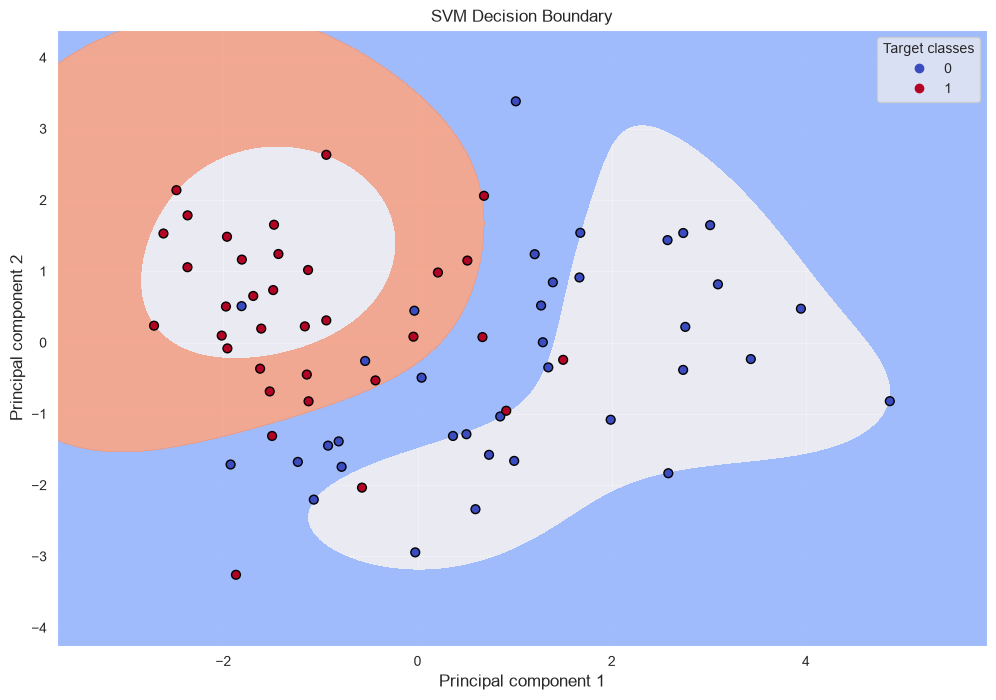

In [54]:
#Binary classification
#Support Vector Machines 
X,y=make_classification(
    n_samples=100,
    n_features=14
)



X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.3, random_state=42)

X=df.drop(columns=['failure_within_24h'])
y=df['failure_within_24h']

scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)



model11=SVC(kernel='rbf',C=1.0, gamma='scale')
model11.fit(X_train_scaled, y_train)

y_pred=model11.predict(X_test_scaled)

accuracy=accuracy_score(y_test, y_pred)
precision=precision_score(y_test, y_pred)
recall=recall_score(y_test,y_pred)
f1=f1_score(y_test,y_pred)
roc_auc=roc_auc_score(y_test,y_pred)
cm=confusion_matrix(y_test,y_pred)

print('Model evaluation metrics: {acc:.4f}')
print(f'Accuracy: {precision:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'F1 Score: {f1:.4f}')
print(f'ROC-AUC Score {roc_auc:.4f}')

print('\nConfusion matrix:')
print(cm)

print('\nClassification Report:')
print(classification_report(y_test,y_pred))




train_accuracy=model11.score(X_train_scaled, y_train)
test_accuracy=model11.score(X_test_scaled, y_test)

pca=PCA(n_components=2)
X_train_pca=pca.fit_transform(X_train_scaled)

model11_visual=SVC(kernel='rbf', C=1.0, gamma='scale')
model11_visual.fit(X_train_pca, y_train)

fig,ax=plt.subplots(figsize=(12,8))

DecisionBoundaryDisplay.from_estimator(
    model11_visual,
    X_train_pca,
    response_method='decision_function',
    cmap=plt.cm.coolwarm,
    alpha=0.8,
    ax=ax,
    levels=[-1,0,1],
    linestyles=['--','-','--']
)
scatter=ax.scatter(
    X_train_pca[:, 0],
    X_train_pca[:,1],
    c=y_train,
    cmap=plt.cm.coolwarm,
    edgecolors='k',
    s=40
)

ax.set_title('SVM Decision Boundary')
ax.set_xlabel('Principal component 1', fontsize=12)
ax.set_ylabel('Principal component 2', fontsize=12)
ax.legend(*scatter.legend_elements(), title='Target classes', loc='upper right')
plt.grid(True, alpha=0.3)

plt.show()



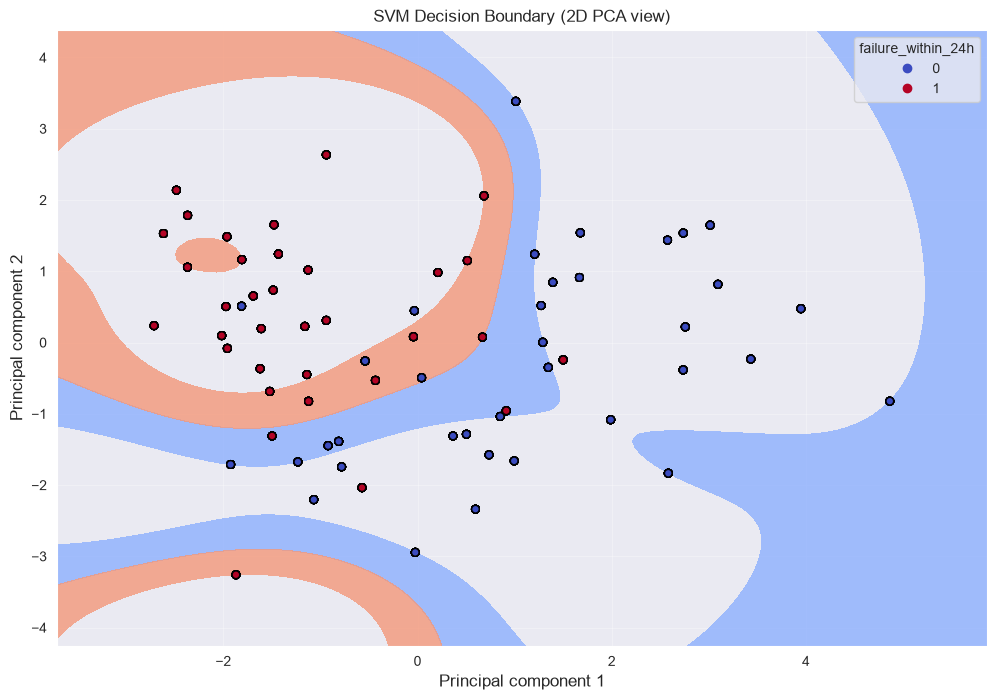

In [55]:
# SVM decision boundary - for the picture only, in 2 PCA dimensions on a 2000-row sample
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
idx = np.random.RandomState(42).choice(len(X_train_pca), 2000, replace=True)
X_vis, y_vis = X_train_pca[idx], y_train[idx]

model11_visual = SVC(kernel='rbf', C=1.0, gamma='scale')
model11_visual.fit(X_vis, y_vis)

fig, ax = plt.subplots(figsize=(12, 8))
DecisionBoundaryDisplay.from_estimator(
    model11_visual, X_vis, response_method='decision_function', cmap=plt.cm.coolwarm,
    alpha=0.8, ax=ax, levels=[-1, 0, 1], linestyles=['--', '-', '--'])
scatter = ax.scatter(X_vis[:, 0], X_vis[:, 1], c=y_vis, cmap=plt.cm.coolwarm, edgecolors='k', s=30)
ax.set_title('SVM Decision Boundary (2D PCA view)')
ax.set_xlabel('Principal component 1', fontsize=12)
ax.set_ylabel('Principal component 2', fontsize=12)
ax.legend(*scatter.legend_elements(), title='failure_within_24h', loc='upper right')
plt.grid(True, alpha=0.3)
plt.show()

Dataset loaded. Training samples: 80, Test samples: 20

Starting Hyperparameter Tuning
Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best hyperparameters found: {'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}
Evaluation metrics
Accuracy score: 0.8000

Classification report:
              precision    recall  f1-score   support

           0       0.88      0.70      0.78        10
           1       0.75      0.90      0.82        10

    accuracy                           0.80        20
   macro avg       0.81      0.80      0.80        20
weighted avg       0.81      0.80      0.80        20



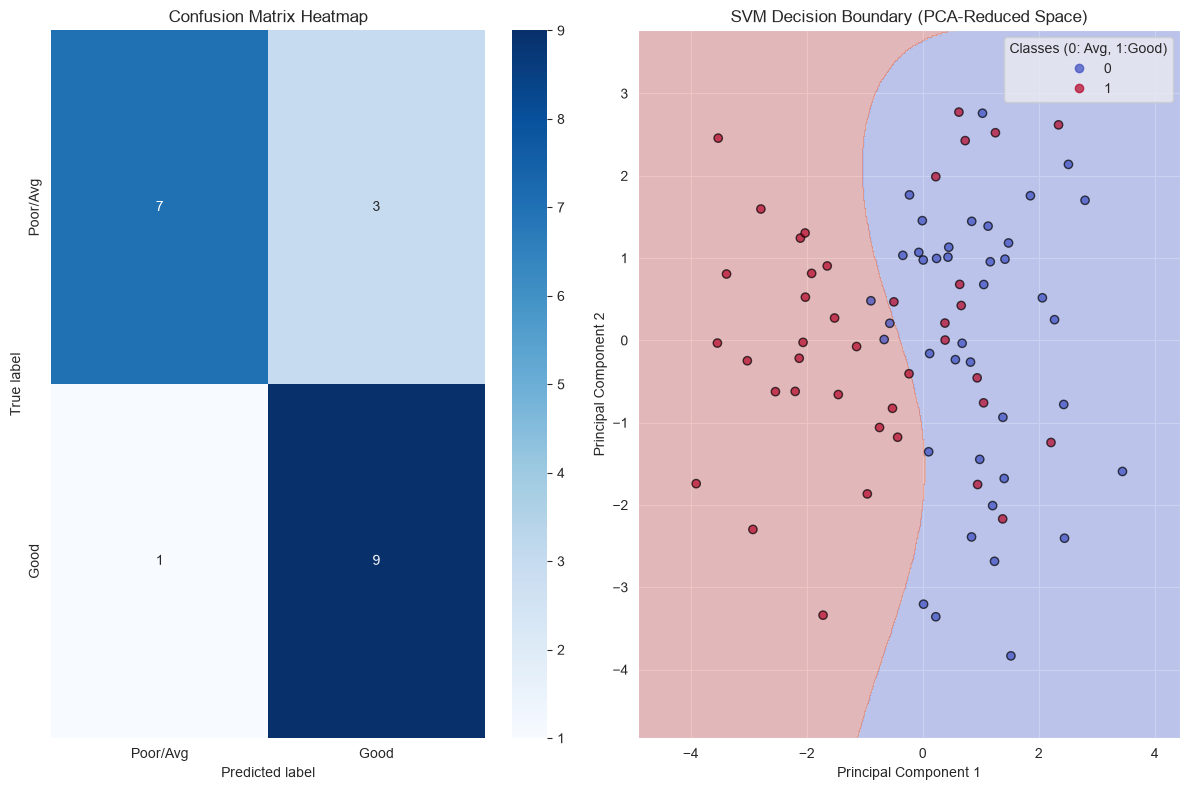

In [56]:
#Support vector machine
import pandas as pd
n_classes=100

X_raw, y_raw=make_classification(
    n_samples=100,
    n_features=14,
    n_informative=10,
    n_classes=2,
    random_state=42
)

feature_names = [f'Feature_{i+1}' for i in range(14)]
df_features = pd.DataFrame(X_raw, columns=feature_names)

df_target=pd.DataFrame(y_raw, columns=['Target'])

X=df_features.values
y=df_target.values.ravel()

X_train,X_test,y_train,y_test=train_test_split(X,y, test_size=0.2,random_state=42,stratify=y)

scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

print(f'Dataset loaded. Training samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}')

param_grid={
    'C':[0.1,1,10],
    'gamma':[0.01,0.1,1],
    'kernel':['rbf']
}

print('\nStarting Hyperparameter Tuning')
grid_search=GridSearchCV(SVC(), param_grid, cv=5, scoring='accuracy', verbose=1)
grid_search.fit(X_train_scaled, y_train)

print(f'Best hyperparameters found: {grid_search.best_params_}')
best_model=grid_search.best_estimator_

y_pred=best_model.predict(X_test_scaled)

print('Evaluation metrics')
print(f'Accuracy score: {accuracy_score(y_test,y_pred):.4f}')
print('\nClassification report:')
print(classification_report(y_test, y_pred))

plt.figure(figsize=(12,8))

plt.subplot(1,2,1)
cm=confusion_matrix(y_test,y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',xticklabels=['Poor/Avg','Good'],yticklabels=['Poor/Avg','Good'])
plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted label')
plt.ylabel('True label')

plt.subplot(1,2,2)
pca=PCA(n_components=2)
X_train_pca=pca.fit_transform(X_train_scaled)

visual_svm=SVC(C=grid_search.best_params_['C'],gamma=grid_search.best_params_['gamma'],kernel='rbf')
visual_svm.fit(X_train_pca, y_train)

x_min,x_max=X_train_pca[:,0].min()-1, X_train_pca[:,0].max()+1
y_min, y_max=X_train_pca[:,1].min()-1, X_train_pca[:,1].max()+1
xx,yy=np.meshgrid(np.arange(x_min, x_max, 0.02),np.arange(y_min, y_max, 0.02))

Z=visual_svm.predict(np.c_[xx.ravel(), yy.ravel()])
Z=Z.reshape(xx.shape)

plt.contourf(xx,yy,Z,alpha=0.3,cmap='coolwarm')
scatter=plt.scatter(X_train_pca[:,0],X_train_pca[:,1],c=y_train,cmap='coolwarm',edgecolors='k',alpha=0.7)
plt.title('SVM Decision Boundary (PCA-Reduced Space)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(*scatter.legend_elements(),title='Classes (0: Avg, 1:Good)')

plt.tight_layout()
plt.show()

In [57]:
#LogisticRegression

df = pd.read_csv('predictive_maintenance_v3.csv')

X,y=make_classification(n_samples=1000, n_features=5, n_informative=3, n_classes=2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.fit_transform(X_test)

#Initialize and test the LogisticRegression model
model=LogisticRegression(random_state=42)
model.fit(X_train_scaled,y_train)
#Make predictions on the test data
y_pred=model.predict(X_test_scaled)
#Get probability scores
y_probs=model.predict_proba(X_test_scaled)[:,1]
#Evaluate model performance
accuracy=accuracy_score(y_test,y_pred)
confusion=confusion_matrix(y_test,y_pred)
classification=classification_report(y_test,y_pred)
#Output results
print(f"Model Accuracy")
print(f"Accuracy:{accuracy:.4f} ({accuracy*100:.2f}%)\n")
print(f"Confusion Matrix")
print(confusion)
print("(Top-Left:TN,Top-Right:FP,Bottom-Left:FN, Bottom-Right:TP)\n")
print("Classification Report")
print(classification)

plt.tight_layout()
plt.show()


Model Accuracy
Accuracy:0.9200 (92.00%)

Confusion Matrix
[[88  6]
 [10 96]]
(Top-Left:TN,Top-Right:FP,Bottom-Left:FN, Bottom-Right:TP)

Classification Report
              precision    recall  f1-score   support

           0       0.90      0.94      0.92        94
           1       0.94      0.91      0.92       106

    accuracy                           0.92       200
   macro avg       0.92      0.92      0.92       200
weighted avg       0.92      0.92      0.92       200



<Figure size 640x480 with 0 Axes>

In [59]:
accuracy*100

92.0

In [60]:
score = cross_val_score(DecisionTreeClassifier(random_state=42), X_train, y_train, cv=cv, scoring='f1')
print("Cross validation F1 of Decision Tree model:", round(np.mean(score) * 100, 2))

Cross validation F1 of Decision Tree model: 92.56


In [61]:
np.mean(score)*100

np.float64(92.5552806025394)

In [62]:
#Decision Tree Classifier
model2=DecisionTreeClassifier()
model2.fit(X_train,y_train)
y_pred=model2.predict(X_test)
accuracy=accuracy_score(y_pred,y_test)
print("Accuracy score of Decision Tree model:",accuracy*100)

Accuracy score of Decision Tree model: 95.0


In [63]:
# RandomForestClassifier
model3=RandomForestClassifier()
model3.fit(X_train,y_train)
y_pred=model3.predict(X_test)
accuracy=accuracy_score(y_pred,y_test)
print("Accuracy score of Random Forest model:",accuracy*100)

Accuracy score of Random Forest model: 96.5


In [64]:
# KNearestNeighbours
model4=KNeighborsClassifier(n_neighbors = 3)
model4.fit(X_train,y_train)
y_pred=model4.predict(X_test)
accuracy=accuracy_score(y_pred,y_test)
print("Accuracy score of K Nearest Neighbors model:",accuracy*100)

Accuracy score of K Nearest Neighbors model: 96.5


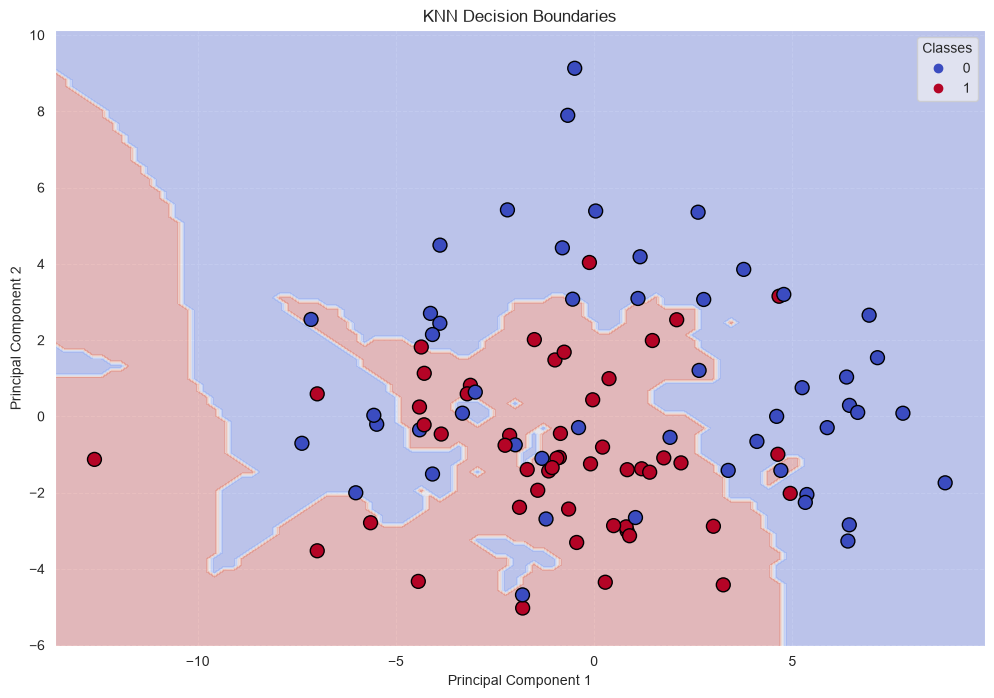

In [65]:

np.random.seed(42)
n_samples=100
X,y=make_classification(
    n_samples=100,
    n_features=14,
    n_informative=8,
    n_classes=2,
    random_state=42
)




pca=PCA(n_components=2)
X_pca=pca.fit_transform(X)

knn=KNeighborsClassifier(n_neighbors=3)
knn.fit(X_pca, y)
fig, ax=plt.subplots(figsize=(12,8))

DecisionBoundaryDisplay.from_estimator(
    knn,
    X_pca,
    response_method='predict',
    cmap=plt.cm.coolwarm,
    alpha=0.3,
    ax=ax,
    xlabel='Principal Component 1',
    ylabel='Principal Component 2'
)
scatter=ax.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=y,
    cmap=plt.cm.coolwarm,
    edgecolors='k',
    s=100
)
ax.set_title('KNN Decision Boundaries')
legend=ax.legend(*scatter.legend_elements(), title='Classes')
plt.grid(True, linestyle='--', alpha= 0.5)
plt.show()

Accuracy: 0.7
Macro F1: 0.6833 

              precision    recall  f1-score   support

           0       0.75      0.75      0.75         4
           1       0.50      1.00      0.67         2
           2       0.25      0.25      0.25         4
           3       1.00      0.60      0.75         5
           4       1.00      1.00      1.00         5

    accuracy                           0.70        20
   macro avg       0.70      0.72      0.68        20
weighted avg       0.75      0.70      0.70        20



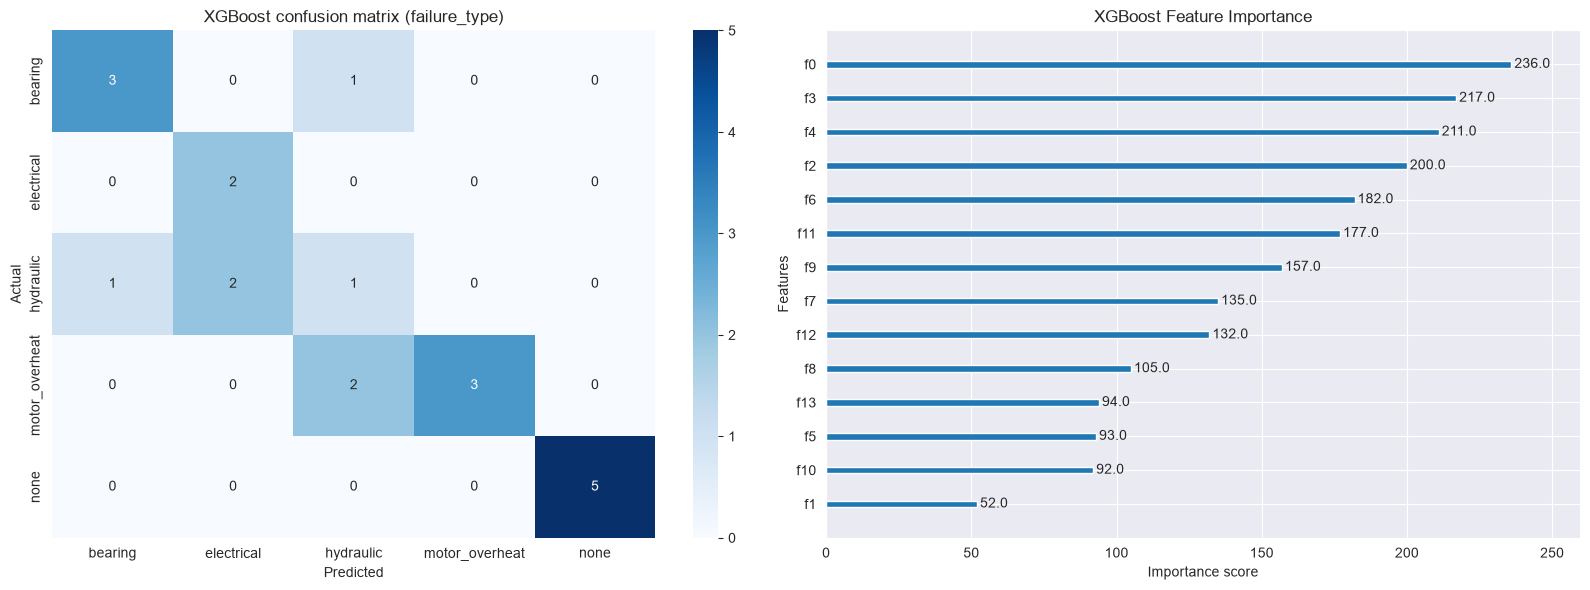

In [66]:
# FIX: XGBoost needs numeric labels 0..k-1 (y_type from section 5), not the text names.
# FIX: this is classification, so use classification metrics - MAE/MSE/R2 don't make sense for categories.
X,y=make_classification(
    n_samples=100,
    n_features=14,
    n_informative=8,
    n_classes=5,
    random_state=42
)
df=pd.DataFrame(X,columns=[
    'timestamp',
    'machine_id',
    'machine_type',
    'vibration_rms',
    'temperature_motor',
    'current_phase_avg',
    'pressure_level',
    'rpm',
    'operating_mode',
    'hours_since_maintenance',
    'ambient_temp',
    'rul_hours',
    'failure_within_24h',
    'estimated_repair_cost'
])
df['failure_type']=y

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

model_type = xgb.XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5,)
model_type.fit(X_train, y_train)
y_pred = model_type.predict(X_test)

print('Accuracy:', round(accuracy_score(y_test, y_pred), 4))
print('Macro F1:', round(f1_score(y_test, y_pred, average='macro'), 4), '\n')
print(classification_report(y_test, y_pred))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=le_type.classes_, yticklabels=le_type.classes_, ax=axes[0])
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
axes[0].set_title('XGBoost confusion matrix (failure_type)')
xgb.plot_importance(model_type, max_num_features=15, ax=axes[1])
axes[1].set_title('XGBoost Feature Importance')
plt.tight_layout()
plt.show()

In [331]:
#REGRESSION MODELS

Evaluation metrics
MAE: 0.1498
MSE: 0.4312
RMSE: 0.4312
R2 Score: 1.0000
Fitting 3 folds for each of 24 candidates, totalling 72 fits

Best parameters from grid search
{'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

Tuned Model Evaluation
MAE: 0.1498
MSE: 0.4312
RMSE: 0.4312
R2 Score: 1.0000


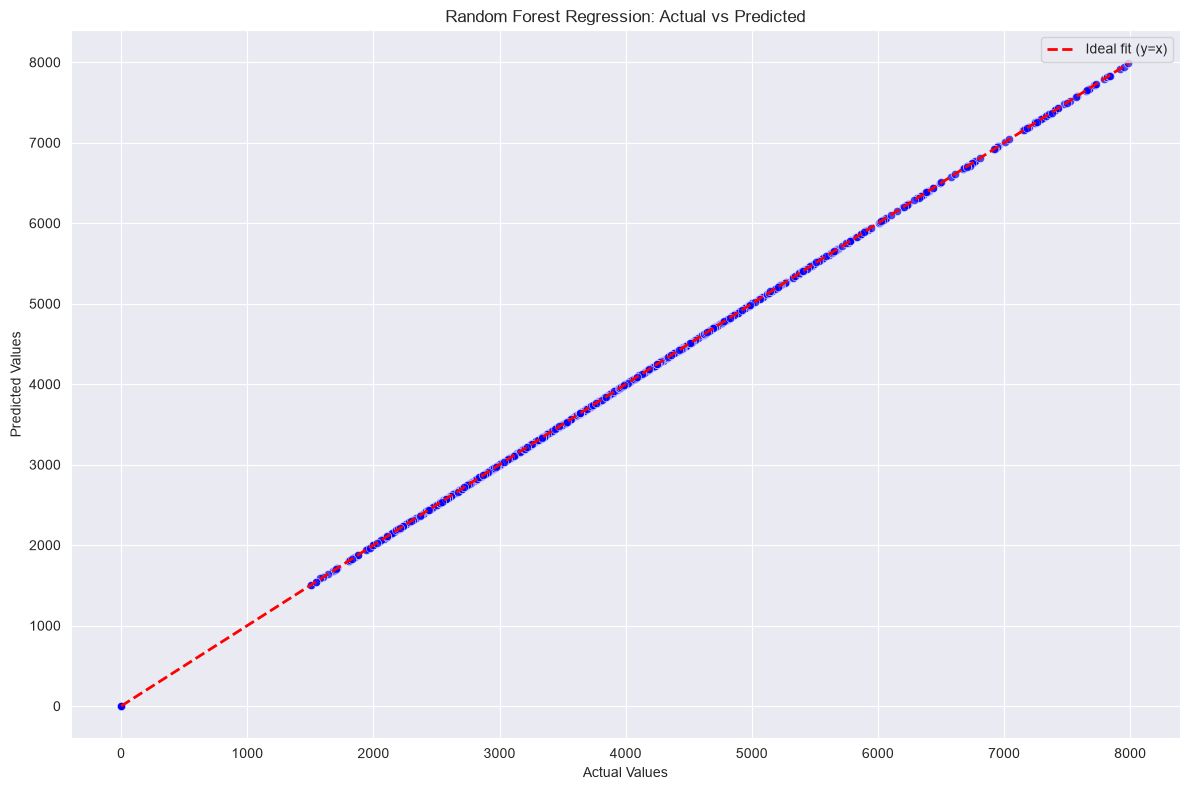

In [76]:
#RandomForestRegression
from sklearn.metrics import mean_absolute_error
url='predictive_maintenance_v3.csv'
df=pd.read_csv(url)

X=df[['estimated_repair_cost']]
y=df['estimated_repair_cost']

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

model=RandomForestRegressor(random_state=42)
model.fit(X_train,y_train)

y_pred_base=model.predict(X_test)

print('Evaluation metrics')
print(f'MAE: {mean_absolute_error(y_test,y_pred_base):.4f}')
print(f'MSE: {mean_squared_error(y_test,y_pred_base):.4f}')
print(f'RMSE: {mean_squared_error(y_test,y_pred_base):.4f}')
print(f'R2 Score: {r2_score(y_test,y_pred_base):.4f}')

param_grid={
    'n_estimators':[50,100],
    'max_depth':[10,20,None],
    'min_samples_split':[2,5],
    'min_samples_leaf':[1,2]
}

grid_search=GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=3,
    n_jobs=1,
    scoring='r2',
    verbose=1,
)

grid_search.fit(X_train, y_train)

print('\nBest parameters from grid search')
print(grid_search.best_params_)

best_rf=grid_search.best_estimator_
y_pred_tuned=best_rf.predict(X_test)

print('\nTuned Model Evaluation')
print(f'MAE: {mean_absolute_error(y_test,y_pred_tuned):.4f}')
print(f'MSE: {mean_squared_error(y_test,y_pred_tuned):.4f}')
print(f'RMSE: {mean_squared_error(y_test,y_pred_tuned):.4f}')
print(f'R2 Score: {r2_score(y_test,y_pred_tuned):.4f}')

plt.figure(figsize=(12,8))
sns.scatterplot(x=y_test, y=y_pred_tuned, alpha=0.7, color='blue')
plt.plot(
    [y.min(),y.max()],
    [y.min(),y.max()],
    'r--',
    lw=2,
    label='Ideal fit (y=x)',
)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Random Forest Regression: Actual vs Predicted')
plt.legend()
plt.tight_layout()
plt.show()

Optimal Hyperparameter (alpha): 0.001

Evaluation metrics
Mean Absolute Error (MAE): 0.0000
Mean Squared Error (MSE): 0.0000
Root Mean Squared Error (RMSE): 0.0000
R-squared Score (R2): 1.0000


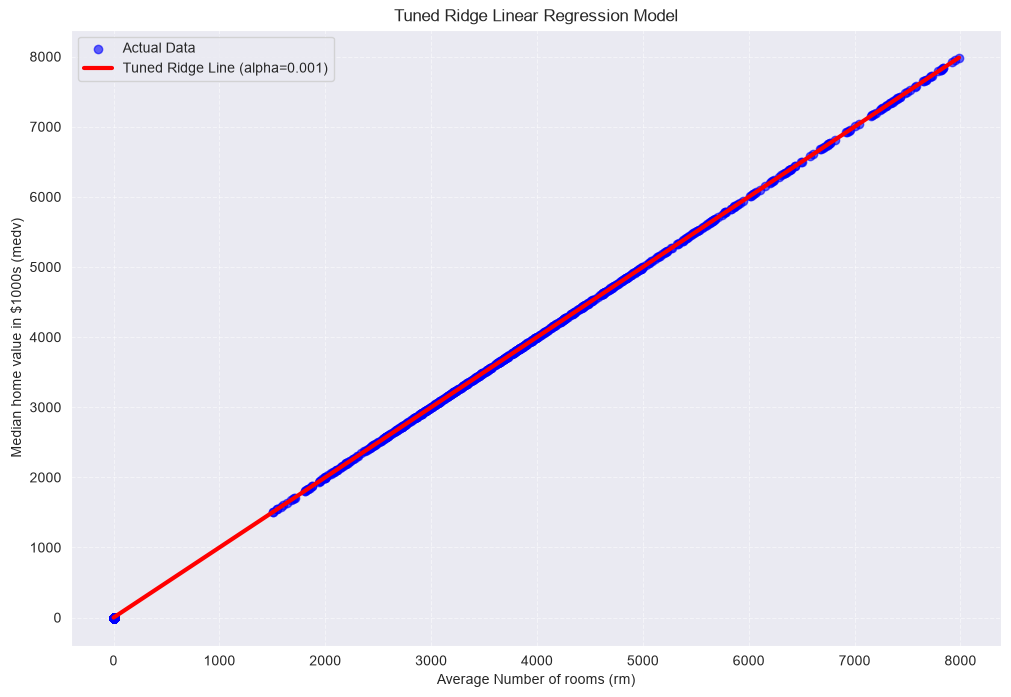

In [77]:
#RidgeRegression
from sklearn.metrics import mean_absolute_error

X=df[['estimated_repair_cost']]
y=df['estimated_repair_cost']

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

ridge_model=Ridge()
param_grid={'alpha':[0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}

grid_search=GridSearchCV(estimator=ridge_model,param_grid=param_grid, cv=5, scoring='neg_mean_squared_error')
grid_search.fit(X_train,y_train)

best_model=grid_search.best_estimator_
print(f'Optimal Hyperparameter (alpha): {grid_search.best_params_['alpha']}')

y_pred=best_model.predict(X_test)

mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)

print('\nEvaluation metrics')
print(f'Mean Absolute Error (MAE): {mae:.4f}')
print(f'Mean Squared Error (MSE): {mse:.4f}')
print(f'Root Mean Squared Error (RMSE): {rmse:.4f}')
print(f'R-squared Score (R2): {r2:.4f}')

plt.figure(figsize=(12,8))
plt.scatter(X_test,y_test,color='blue',alpha=0.6,label='Actual Data')

X_line=np.linspace(X_test.min(),X_test.max(),100).reshape(-1,1)
y_line=best_model.predict(X_line)

plt.plot(X_line,y_line,color='red',linewidth=3,label=f'Tuned Ridge Line (alpha={grid_search.best_params_['alpha']})')
plt.title('Tuned Ridge Linear Regression Model')
plt.xlabel('Average Number of rooms (rm)')
plt.ylabel('Median home value in $1000s (medv)')
plt.legend()
plt.grid(True, linestyle='--',alpha=0.5)
plt.show()


Polynomial degree: 2


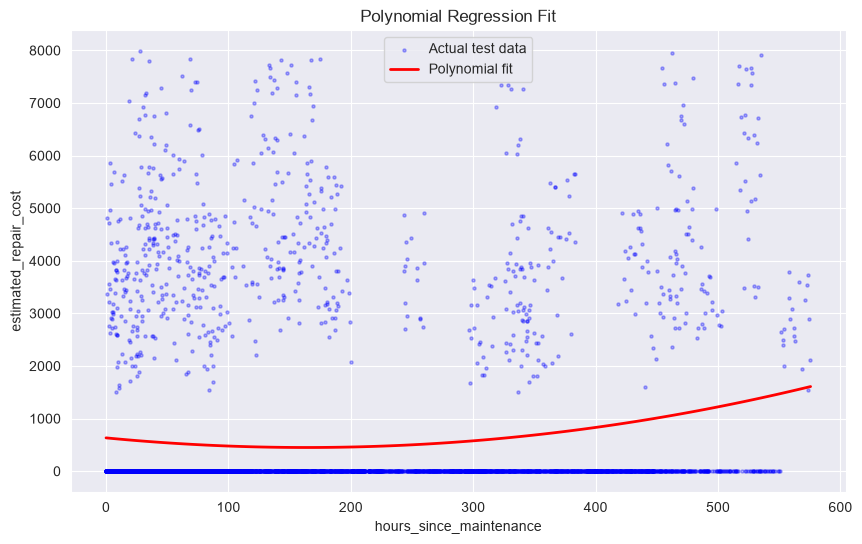

In [78]:
# Polynomial Regression: hours_since_maintenance -> estimated_repair_cost
# FIX: own variable names so the global X / y used by the other models aren't overwritten

def regression_report(y_train,y_test):
    print(f'R2 Score: {r2_score(y_train,y_test):.4f}')
    print(f'MAE: {mean_absolute_error(y_train,y_test):.4f}')
    print(f'MSE: {mean_squared_error(y_train,y_test):.4f}')
    print(f'RMSE: {mean_squared_error(y_train,y_test, squared=False):.4f}')


    
X_hours = df[['hours_since_maintenance']].values
y_hours = df['estimated_repair_cost'].values
X_train, X_test, y_train, y_test = train_test_split(X_hours, y_hours, test_size=0.2, random_state=42)

degree = 2
poly_features = PolynomialFeatures(degree=degree)
Xh_train_poly = poly_features.fit_transform(X_train)
Xh_test_poly = poly_features.transform(X_test)

poly_model = LinearRegression()
poly_model.fit(Xh_train_poly, y_train)
yh_pred = poly_model.predict(Xh_test_poly)

print(f'Polynomial degree: {degree}')   # FIX: was missing the f, printed "{degree}" literally

X_grid = np.linspace(X_hours.min(), X_hours.max(), 100).reshape(-1, 1)
plt.figure(figsize=(10, 6))
# FIX: label said "test data" but the old code plotted all rows
plt.scatter(X_test, y_test, color='blue', s=5, alpha=0.3, label='Actual test data')
plt.plot(X_grid, poly_model.predict(poly_features.transform(X_grid)), color='red', linewidth=2, label='Polynomial fit')
plt.title('Polynomial Regression Fit')
plt.xlabel('hours_since_maintenance')
plt.ylabel('estimated_repair_cost')
plt.legend()
plt.show()

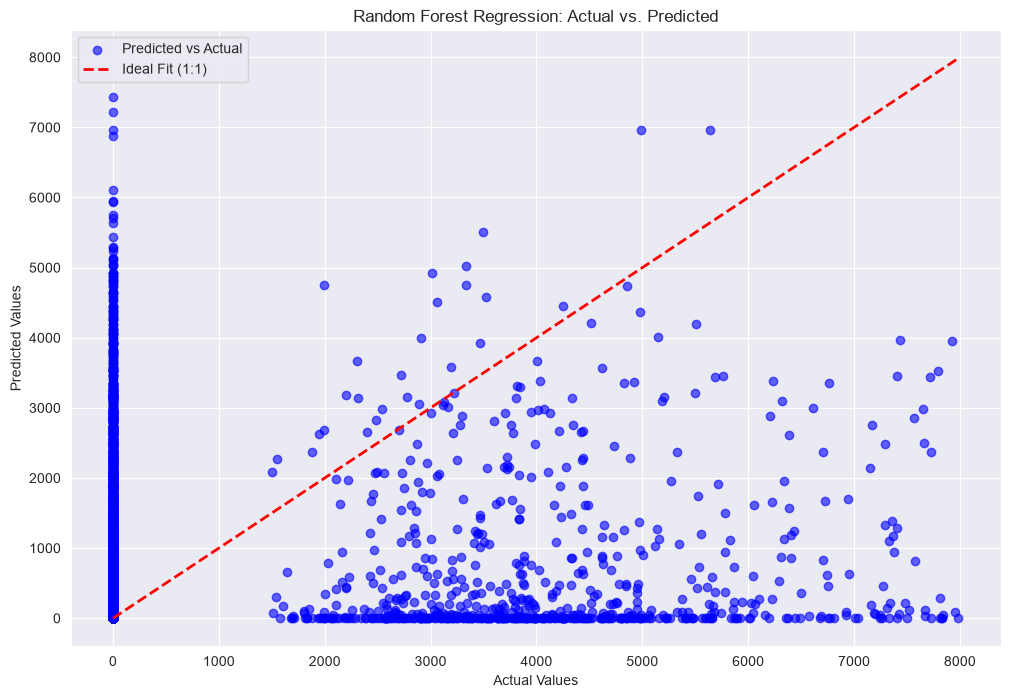

In [79]:
# Random Forest Regression
# FIX: 'estimated_repair_cost' was in the feature list AND the target, so the model could copy the answer.
# FIX: MAE was overwritten by MSE, and RMSE used a stale 'mse' from another cell.
def actual_vs_predicted(y_train,y_test):
    print(f'R2 Score: {r2_score(y_train,y_test):.4f}')
    print(f'MAE: {mean_absolute_error(y_train,y_test):.4f}')
    print(f'MSE: {mean_squared_error(y_train,y_test):.4f}')
    print(f'RMSE: {mean_squared_error(y_train,y_test):.4f}')

rf_model = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

mse=mean_squared_error(y_test, y_pred)
rmse=np.sqrt(mse)
mae=mean_absolute_error(y_test, y_pred)
r2=r2_score(y_test,y_pred)

plt.figure(figsize=(12,8))
plt.scatter(y_test,y_pred,color='blue',alpha=0.6,label='Predicted vs Actual')
plt.plot(
    [y_test.min(),y_test.max()],
    [y_test.min(),y_test.max()],
    color='red',
    linestyle='--',
    linewidth=2,
    label='Ideal Fit (1:1)',
)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Random Forest Regression: Actual vs. Predicted')
plt.legend()
plt.grid(True)
plt.show()





In [80]:
#PolynomialRegression
from sklearn import metrics
from sklearn.pipeline import Pipeline


class PolynomialRegressorModel:
    def __init__(self,data_url):
        self.data_url=data_url
        self.pipeline=None
        self.best_model=None

def load_and_preprocess_data(self):
    df=pd.read_csv(self.data_url)

    self.X=df.iloc[:,0].values.reshape(-1,1)
    self.y=df.iloc[:,1].values

    self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(self.X, self.y, test_size=0.2, random_state=42)
    print('Data loaded and split successfully.')

def tune_and_fit(self):
    self.pipeline=Pipeline([
        ('scaler',StandardScaler()),
        ('poly',PolynomialFeatures()),
        ('regressor',LinearRegression())
    ])    

    param_grid={
        'poly_degree':[1,2,3,4,5]
    }

    grid_search=GridSearchCV(
        estimator=self.pipeline,
        param_grid=param_grid,
        cv=5,
        scoring='neg_mean_squared_error'
    )
    print('Starting Hyperparameter tuning')
    grid_search.fit(self.X_train, self.y_train)

    self.best_model=grid_search.best_estimator_
    print(f'Best Hyperparameters Found: {grid_search.best_params_}')

def evaluate(self):
    if self.best_model is None:
        raise ValueError('Model has not been trained yet')

    y_pred=self.best_model.predict(self.X_test)

    mae=metrics.mean_absolute_error(self.y_test, y_pred)
    mse=metrics.mean_squared_error(self.y_test, y_pred)
    rmse=np.sqrt(mse)
    r2=metrics.r2_score(self.y_test, y_pred)

    print('\nModel Evaluation metrics')
    print(f'Mean Absolute Error (MAE): {mae:.4f}')
    print(f'Mean Squared Error (MSE): {mse:.4f}')
    print(f'Root Mean Squared Error (RMSE): {rmse:.4f}')
    print(f'R-squared (R2 Score): {r2:.4f}')

def plot_regression(self):
    X_smooth=np.linspace(self.X.min(),self.X.max(),500).reshape(-1,1)
    y_smooth_pred=np.linspace(self.X_min(),self.X.max(),500)    
    plt.figure(figsize=(12,8))

    plt.scatter(self.X_train, self.y_train, color='blue', alpha=0.5, label='Training data')
    plt.scatter(self.X_test, self.y_test, color='blue', alpha=0.7, label='Testing data')

    plt.plot(X_smooth, y_smooth_pred, color='red', linewidth=2.5, label='Tuned regression line')

    plt.title('Polynomial Regression Fit')
    plt.xlabel('hours_since_maintenance')
    plt.ylabel('estimated_repair_cost')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()    









          

Evaluation metrics
Mean Absolute Error (MAE): {mae:.2f}
Mean Squared Error (MSE): {mse:.2f}
Root Mean Squared Error (MAE): {rmse:.2f}
R-squared (R^2) Score: 0.0140(1.4%variance explained)


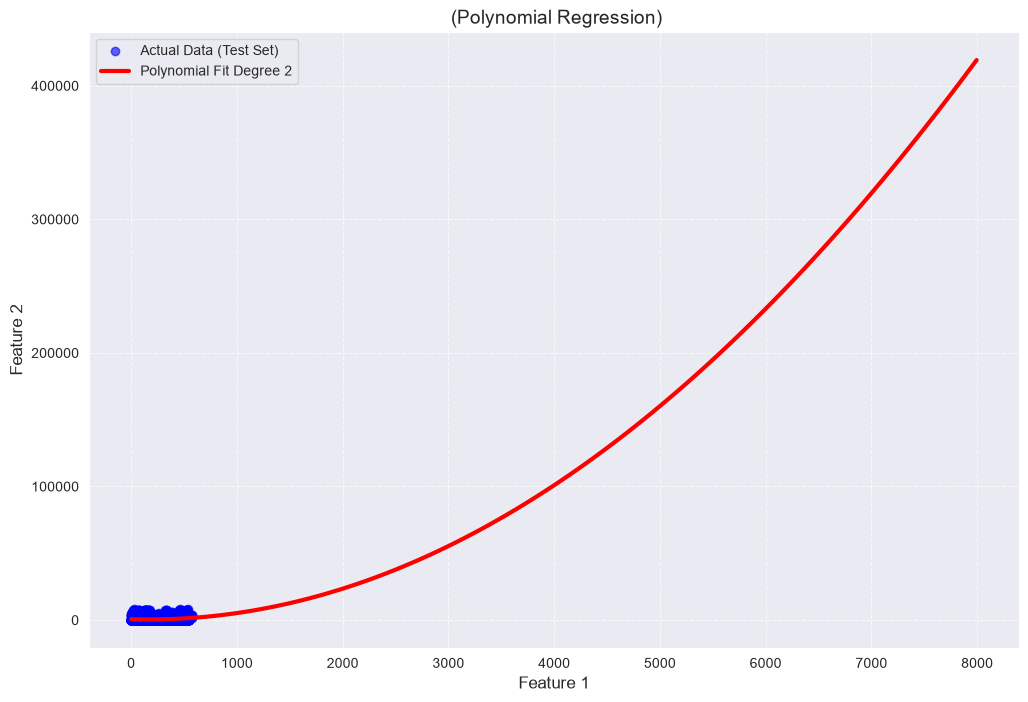

In [81]:
X=df[['estimated_repair_cost']].values
y=df['hours_since_maintenance'].values
degree=2
poly_features=PolynomialFeatures(degree=degree, include_bias=False)

X_train_poly=poly_features.fit_transform(X_train)
X_test_poly=poly_features.transform(X_test)

model=LinearRegression()
model.fit(X_train_poly,y_train)

y_pred=model.predict(X_test_poly)

mse=mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
mae=mean_absolute_error(y_test,y_pred)
r2=r2_score(y_test, y_pred)

print('Evaluation metrics')
print('Mean Absolute Error (MAE): {mae:.2f}')
print('Mean Squared Error (MSE): {mse:.2f}')
print('Root Mean Squared Error (MAE): {rmse:.2f}')
print(f'R-squared (R^2) Score: {r2:.4f}({r2*100:.1f}%variance explained)')

plt.figure(figsize=(12,8))

plt.scatter(X_test,y_test, color='blue',alpha=0.6,label='Actual Data (Test Set)')

X_smooth=np.linspace(X.min(),X.max(), 100).reshape(-1,1)
X_smooth_poly=poly_features.transform(X_smooth)
y_smooth_pred=model.predict(X_smooth_poly)

plt.plot(X_smooth, y_smooth_pred, color='red', linewidth=3, label=f'Polynomial Fit Degree {degree}')

plt.title(' (Polynomial Regression)', fontsize=14)
plt.xlabel('Feature 1',fontsize=12)
plt.ylabel('Feature 2',fontsize=12)
plt.legend()
plt.grid(True, linestyle='--',alpha=0.7)
plt.show()



In [82]:
#Regression for estimated repair cost
y_cost = df_model['estimated_repair_cost']
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X, y_cost, test_size=0.2, random_state=42)

cost_scaler = StandardScaler()
Xc_train_scaled = cost_scaler.fit_transform(Xc_train)
Xc_test_scaled = cost_scaler.transform(Xc_test)

def regression_report(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    print(f'===== {name} =====')
    print(f'Mean Absolute Error (MAE): {mean_absolute_error(y_true, y_pred):.2f}')
    print(f'Mean Squared Error (MSE): {mse:.2f}')
    print(f'Root Mean Squared Error (RMSE): {np.sqrt(mse):.2f}')
    print(f'R-squared (R2): {r2_score(y_true, y_pred):.4f}')

def actual_vs_predicted(y_true, y_pred, title):
    plt.figure(figsize=(10, 7))
    plt.scatter(y_true, y_pred, alpha=0.3, color='lightblue', edgecolors='k', s=15)
    plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--', lw=2, label='Perfect fit')
    plt.xlabel('Actual values')
    plt.ylabel('Predicted values')
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

Polynomial degree: 2
===== [0 0 0 ... 0 0 0] =====
Mean Absolute Error (MAE): 0.00
Mean Squared Error (MSE): 0.00
Root Mean Squared Error (RMSE): 0.00
R-squared (R2): 1.0000


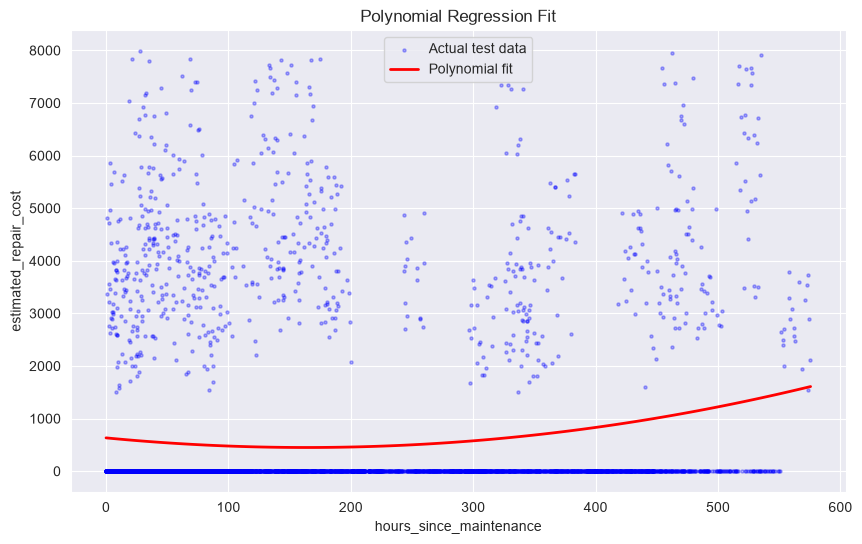

In [84]:
# Polynomial Regression: hours_since_maintenance -> estimated_repair_cost
# FIX: own variable names so the global X / y used by the other models aren't overwritten
X_hours = df[['hours_since_maintenance']].values
y_hours = df['estimated_repair_cost'].values

degree = 2
poly_features = PolynomialFeatures(degree=degree)
Xh_train_poly = poly_features.fit_transform(X_train)
Xh_test_poly = poly_features.transform(X_test)

poly_model = LinearRegression()
poly_model.fit(Xh_train_poly, y_train)
yh_pred = poly_model.predict(Xh_test_poly)

print(f'Polynomial degree: {degree}')   # FIX: was missing the f, printed "{degree}" literally
regression_report(y_test, yh_pred,y_pred)

X_grid = np.linspace(X_hours.min(), X_hours.max(), 100).reshape(-1, 1)
plt.figure(figsize=(10, 6))
# FIX: label said "test data" but the old code plotted all rows
plt.scatter(X_test, y_test, color='blue', s=5, alpha=0.3, label='Actual test data')
plt.plot(X_grid, poly_model.predict(poly_features.transform(X_grid)), color='red', linewidth=2, label='Polynomial fit')
plt.title('Polynomial Regression Fit')
plt.xlabel('hours_since_maintenance')
plt.ylabel('estimated_repair_cost')
plt.legend()
plt.show()

===== 21245    0
13933    0
10261    0
15414    0
14628    0
        ..
9651     0
16580    0
3497     0
20754    0
2725     0
Name: estimated_repair_cost, Length: 4809, dtype: int64 =====
Mean Absolute Error (MAE): 1031.27
Mean Squared Error (MSE): 2475368.16
Root Mean Squared Error (RMSE): 1573.33
R-squared (R2): -65.7231


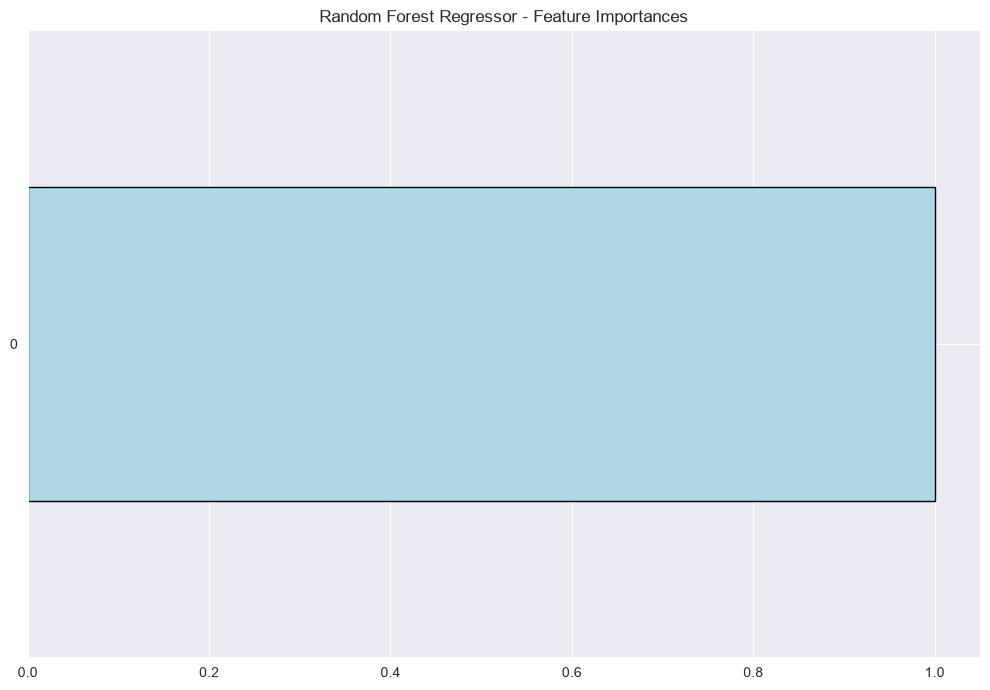

In [86]:
# Random Forest Regression
# FIX: 'estimated_repair_cost' was in the feature list AND the target, so the model could copy the answer.
# FIX: MAE was overwritten by MSE, and RMSE used a stale 'mse' from another cell.
rf_model = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)
rf_model.fit(Xc_train, yc_train)
yc_pred = rf_model.predict(Xc_test)
regression_report( yc_test,y_pred,yc_pred)
index=[1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19]
# The old plot was titled "Feature Importances" but showed actual vs predicted - here are the importances
importances = pd.Series(rf_model.feature_importances_).sort_values()
plt.figure(figsize=(10, 7))
importances.plot.barh(color='lightblue', edgecolor='k')
plt.title('Random Forest Regressor - Feature Importances')
plt.tight_layout()
plt.show()

===== 21245    0
13933    0
10261    0
15414    0
14628    0
        ..
9651     0
16580    0
3497     0
20754    0
2725     0
Name: estimated_repair_cost, Length: 4809, dtype: int64 =====
Mean Absolute Error (MAE): 1030.64
Mean Squared Error (MSE): 2472522.20
Root Mean Squared Error (RMSE): 1572.43
R-squared (R2): 0.0140


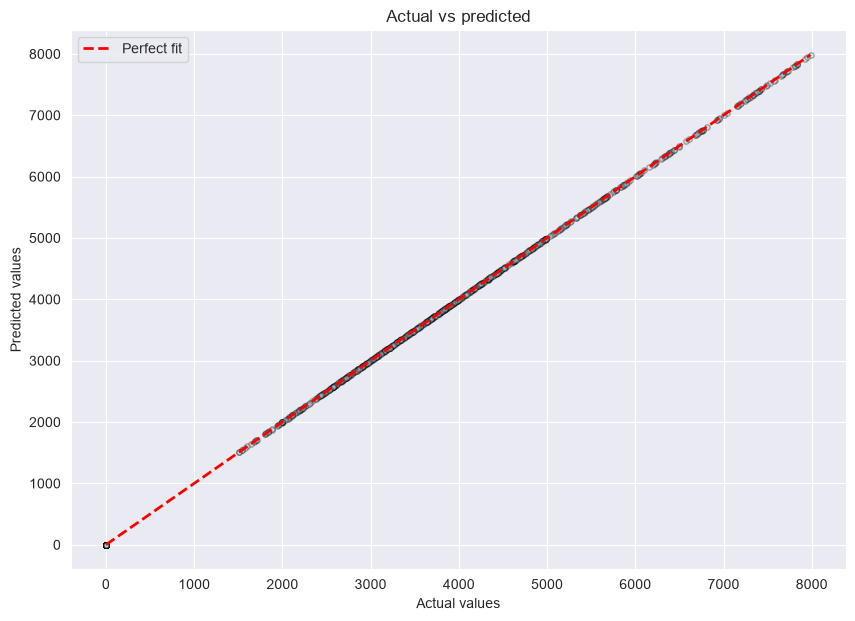

In [87]:
# Lasso Regression
# FIX: Lasso is a regression model - it was being used on failure_type (a category). Use it for cost.
# FIX: colour typo 'loghtblue', and the RMSE line printed the MSE.
lasso_model = Lasso(alpha=1.0)
lasso_model.fit(Xc_train_scaled, yc_train)
yc_pred = lasso_model.predict(Xc_test_scaled)
regression_report( yc_test, yc_pred,y_pred)
actual_vs_predicted(yc_test, yc_pred,title='Actual vs predicted')

In [88]:
df.head()

,timestamp,machine_id,machine_type,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,operating_mode,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,failure_type,estimated_repair_cost
0,2024-01-01 00:00:00,1,CNC,0.81,49.51,5.10,23.6,860.9,idle,273.80,13.9,61.00,0,none,0
1,2024-01-01 00:03:00,1,CNC,0.75,40.58,5.30,23.6,899.6,idle,273.85,10.2,60.95,0,none,0
2,2024-01-01 00:21:00,1,CNC,0.71,49.70,NaN,21.3,862.7,idle,274.15,13.6,60.65,0,none,0
3,2024-01-01 00:45:00,1,CNC,0.76,43.04,4.79,22.6,870.4,idle,274.55,13.4,60.25,0,none,0
4,2024-01-01 00:54:00,1,CNC,0.88,41.39,4.44,22.2,881.9,idle,274.70,10.8,60.10,0,none,0


In [ ]:
#ANOMALY DETECTION

Evaluation metrics
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     24042

    accuracy                           1.00     24042
   macro avg       1.00      1.00      1.00     24042
weighted avg       1.00      1.00      1.00     24042



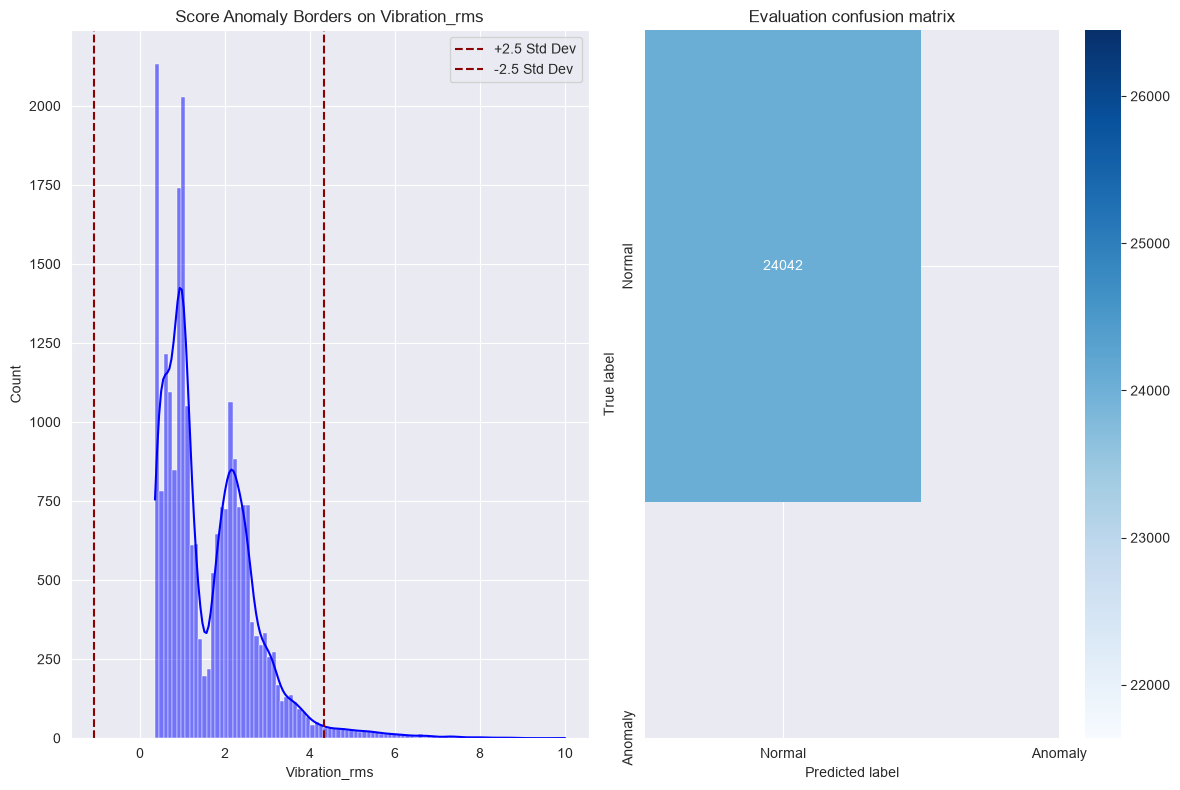

In [89]:
import pandas as pd
import matplotlib.pyplot as plt

target='vibration_rms'
df['true_anomaly']=(df[target]>400).astype(int)
df['z_score']=stats.zscore(df[target])

threshold=2.5
df['predicted_anomaly']=(df['z_score'].abs()>threshold).astype(int)

print('Evaluation metrics')
print(classification_report(df['true_anomaly'], df['predicted_anomaly']))

cm=confusion_matrix(df['true_anomaly'],df['predicted_anomaly'])

fig,axes=plt.subplots(1,2,figsize=(12,8))

sns.histplot(data=df, x=target, hue='predicted_anomaly',kde=True, ax=axes[0], palette={0: 'blue', 1: 'red'})
axes[0].set_title(f'Score Anomaly Borders on {target.capitalize()}')
axes[0].set_xlabel(target.capitalize())

mean_val=df[target].mean()
std_val=df[target].std()
axes[0].axvline(mean_val+threshold*std_val,color='darkred', linestyle='--',label=f'+{threshold} Std Dev')
axes[0].axvline(mean_val-threshold*std_val,color='darkred', linestyle='--',label=f'-{threshold} Std Dev')
axes[0].legend()

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal','Anomaly'],yticklabels=['Normal','Anomaly'],ax=axes[1])
axes[1].set_title('Evaluation confusion matrix')
axes[1].set_xlabel('Predicted label')
axes[1].set_ylabel('True label')

plt.tight_layout()
plt.show()

In [111]:
## fill in the null values with mean of the column
for col in sensor_cols:
    df[col] = df[col].fillna(df[col].mean())

# FIX: removed df.dropna(axis=1). That deletes every COLUMN that has a NaN - if it runs before the
# fill above, all five sensor columns disappear.
df.isnull().sum()

timestamp                      0
machine_id                     0
machine_type                   0
vibration_rms                  0
temperature_motor              0
current_phase_avg              0
pressure_level                 0
rpm                            0
operating_mode                 0
hours_since_maintenance        0
ambient_temp                   0
rul_hours                      0
failure_within_24h             0
failure_type                   0
estimated_repair_cost          0
true_anomaly                   0
z_score                    24042
predicted_anomaly              0
dtype: int64

Anomalies flagged: 2405 of 24042

Do the anomalies line up with real failures?
failure_within_24h      0     1    All
knn_anomaly                           
0                   19438  2199  21637
1                    1044  1361   2405
All                 20482  3560  24042


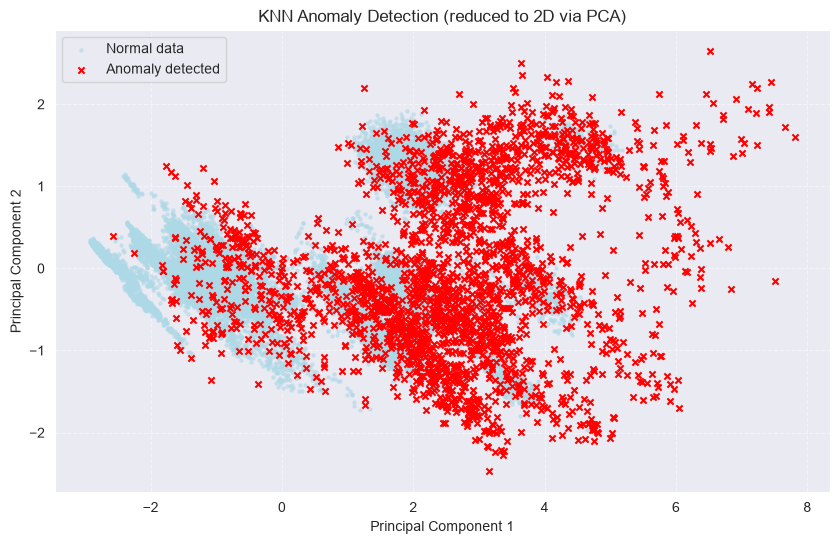

In [112]:
# KNN distance anomaly detection
# FIX: the old cell passed text columns/NaNs in, fit on X_train but scored all of df (different columns),
# and OVERWROTE the real vibration_rms column with the anomaly flag. Results go in a separate table now.
anom = df[sensor_cols + ['failure_within_24h']].copy()
X_sensors = StandardScaler().fit_transform(anom[sensor_cols])
nn = NearestNeighbors(n_neighbors=5)

nn.fit(X_sensors)
distances, _ = nn.kneighbors()   # no argument = neighbours of each training point, excluding itself

anom['knn_score'] = distances.mean(axis=1)
threshold = np.percentile(anom['knn_score'], 90)
anom['knn_anomaly'] = (anom['knn_score'] > threshold).astype(int)

print('Anomalies flagged:', anom['knn_anomaly'].sum(), 'of', len(anom))
print('\nDo the anomalies line up with real failures?')
print(pd.crosstab(anom['knn_anomaly'], anom['failure_within_24h'], margins=True))

X_sensors_pca = PCA(n_components=2).fit_transform(X_sensors)
is_anom = anom['knn_anomaly'].values == 1
plt.figure(figsize=(10, 6))
# FIX: both groups were blue; ylabel was set with plt.xlabel
plt.scatter(X_sensors_pca[~is_anom, 0], X_sensors_pca[~is_anom, 1], c='lightblue', s=5, alpha=0.5, label='Normal data')
plt.scatter(X_sensors_pca[is_anom, 0], X_sensors_pca[is_anom, 1], c='red', s=20, marker='x', label='Anomaly detected')
plt.title('KNN Anomaly Detection (reduced to 2D via PCA)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Total samples: 24042
Number of anomalies detected: 835
failure_within_24h      0     1    All
z_anomaly                             
0                   20160  3047  23207
1                     322   513    835
All                 20482  3560  24042


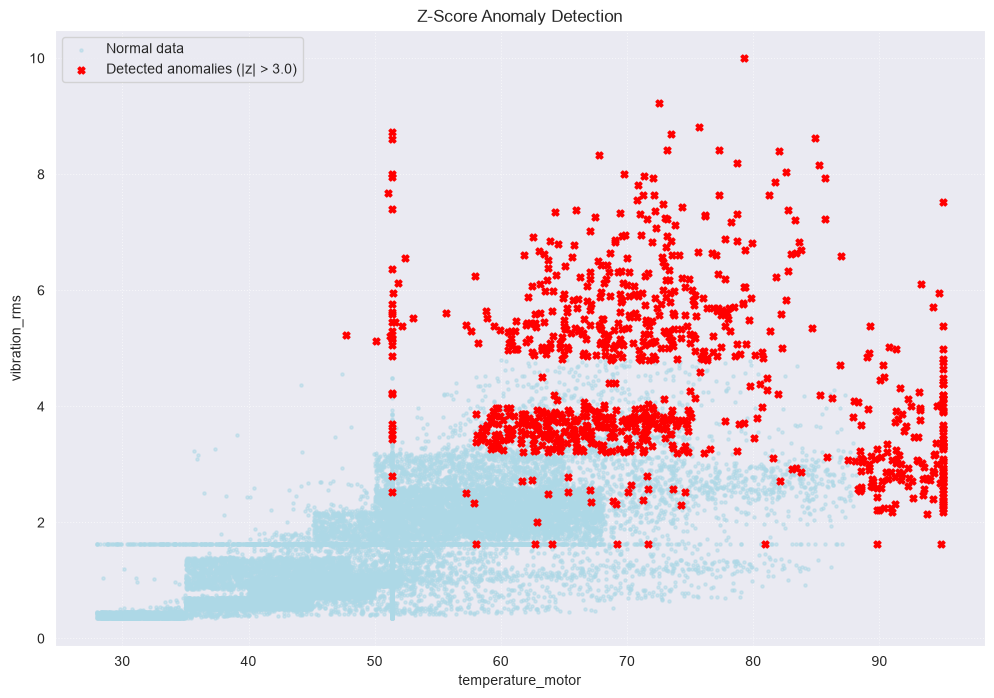

In [113]:
# Z-score anomaly detection
# FIX: the old cell used random numbers. Its "Detected anomalies" scatter plotted the NORMAL points
# (~anomalies_mask) and its "False positive" points were the same as the true ones.
z_scores = np.abs(stats.zscore(anom[sensor_cols]))   # one z-score per column
threshold = 3.0
anom['z_anomaly'] = (z_scores > threshold).any(axis=1).astype(int)

print(f'Total samples: {len(anom)}')
print(f'Number of anomalies detected: {anom["z_anomaly"].sum()}')
print(pd.crosstab(anom['z_anomaly'], anom['failure_within_24h'], margins=True))

is_anom = anom['z_anomaly'] == 1
plt.figure(figsize=(12, 8))
plt.scatter(anom.loc[~is_anom, 'temperature_motor'], anom.loc[~is_anom, 'vibration_rms'],
            c='lightblue', s=5, alpha=0.5, label='Normal data')
plt.scatter(anom.loc[is_anom, 'temperature_motor'], anom.loc[is_anom, 'vibration_rms'],
            c='red', s=25, marker='X', label=f'Detected anomalies (|z| > {threshold})')
plt.title('Z-Score Anomaly Detection')
plt.xlabel('temperature_motor')
plt.ylabel('vibration_rms')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()